# AI Impact on Jobs & Layoff Risk Analysis
### Full Pipeline — Month-1 (Cleaning) → Month-2 (EDA + Features + ML Prep) → Month-3 (Modeling)

In [19]:
import sys, os
sys.path.append(os.path.abspath(".."))

import config
print("Dataset:", config.RAW_DATASET_PATH)

Dataset: C:\Users\Easyskill-Saurabh\Desktop\AI-Impact-Jobs-Layoff-Risk\data\raw\ai-impact-jobs-layoff-risk-dataset.csv


## Month-1: Data Loading & Inspection

In [20]:
import sys, os
sys.path.append(os.path.abspath(".."))

from src.data_loading import (
    load_dataset,
    inspect_dataset,
    display_shape,
    display_columns,
    display_data_types,
    display_missing_values,
)

df = load_dataset(config.RAW_DATASET_PATH)
display_shape(df)
display_columns(df)
display_data_types(df)
display_missing_values(df)
inspect_dataset(df)

[OK] File found: C:\Users\Easyskill-Saurabh\Desktop\AI-Impact-Jobs-Layoff-Risk\data\raw\ai-impact-jobs-layoff-risk-dataset.csv

Loading dataset from: C:\Users\Easyskill-Saurabh\Desktop\AI-Impact-Jobs-Layoff-Risk\data\raw\ai-impact-jobs-layoff-risk-dataset.csv
[OK] Dataset loaded successfully!

Dataset Shape: 20000 rows x 16 columns

Column Names (16 columns):
  1. Age
  2. Education_Level
  3. Years_of_Experience
  4. Industry
  5. Job_Role
  6. Company_Size
  7. Job_Level
  8. Routine_Task_Percentage
  9. Creativity_Requirement
  10. Human_Interaction_Level
  11. AI_Adoption_Level
  12. Number_of_AI_Tools_Used
  13. AI_Usage_Hours_Per_Week
  14. Tasks_Automated_Percentage
  15. AI_Training_Hours
  16. Layoff_Risk

Column Data Types:
----------------------------------------
  Age: int64
  Education_Level: str
  Years_of_Experience: int64
  Industry: str
  Job_Role: str
  Company_Size: str
  Job_Level: str
  Routine_Task_Percentage: int64
  Creativity_Requirement: int64
  Human_Interact

## Month-1: Data Cleaning

In [21]:
import sys, os
sys.path.append(os.path.abspath(".."))

from src.data_cleaning import (
    handle_missing_values,
    remove_duplicates,
    remove_invalid_records,
    standardize_column_names,
    save_clean_dataset,
)

df = handle_missing_values(df, strategy="drop")
df = remove_duplicates(df)
df = remove_invalid_records(df)
df = standardize_column_names(df)
save_clean_dataset(df, config.CLEANED_DATASET_PATH)
print("Cleaned shape:", df.shape)


HANDLING MISSING VALUES

Missing values before cleaning: 0

Strategy: Drop rows with missing values
Rows dropped: 0

Missing values after cleaning: 0
Rows: 20000 -> 20000

REMOVING DUPLICATES

Duplicate rows found: 0
No duplicates found. Dataset is clean.

REMOVING INVALID RECORDS

Total invalid records removed: 0
Remaining valid records: 20000

STANDARDIZING COLUMN NAMES

Column Name Changes:
--------------------------------------------------
  'Age' -> 'age'
  'Education_Level' -> 'education_level'
  'Years_of_Experience' -> 'years_of_experience'
  'Industry' -> 'industry'
  'Job_Role' -> 'job_role'
  'Company_Size' -> 'company_size'
  'Job_Level' -> 'job_level'
  'Routine_Task_Percentage' -> 'routine_task_percentage'
  'Creativity_Requirement' -> 'creativity_requirement'
  'Human_Interaction_Level' -> 'human_interaction_level'
  'AI_Adoption_Level' -> 'ai_adoption_level'
  'Number_of_AI_Tools_Used' -> 'number_of_ai_tools_used'
  'AI_Usage_Hours_Per_Week' -> 'ai_usage_hours_per_week

## Month-2: Exploratory Data Analysis

In [22]:
import sys, os
sys.path.append(os.path.abspath(".."))

from src.exploratory_data_analysis import run_complete_eda

eda_results = run_complete_eda(df)


######################################################################
# EXPLORATORY DATA ANALYSIS
######################################################################

BASIC STATISTICAL SUMMARY

--- Numerical Columns ---
                age  years_of_experience  routine_task_percentage  \
count  20000.000000         20000.000000             20000.000000   
mean      40.361500             7.265500                51.885500   
std       11.526333             4.720606                24.437808   
min       21.000000             0.000000                10.000000   
25%       30.000000             4.000000                31.000000   
50%       40.000000             7.000000                52.000000   
75%       50.000000            11.000000                73.000000   
max       60.000000            32.000000                94.000000   

       creativity_requirement  human_interaction_level  \
count            20000.000000             20000.000000   
mean                47.786700        

## Month-2: Feature Engineering

In [23]:
import sys, os
sys.path.append(os.path.abspath(".."))

from src.feature_engineering import run_feature_engineering

df_engineered = run_feature_engineering(df)
df_engineered.head()


######################################################################
# FEATURE ENGINEERING
######################################################################

[Feature Engineering] Creating experience categories...
  Created 'experience_category' with 4 categories

[Feature Engineering] Creating age groups...
  Created 'age_group' with 5 groups

[Feature Engineering] Creating AI intensity score...
  Created 'ai_intensity_score' (range: 1.5 - 96.4)

[Feature Engineering] Creating routine-creativity ratio...
  Created 'routine_creativity_ratio' (range: 0.10 - 94.00)

[Feature Engineering] Creating human-AI balance score...
  Created 'human_ai_balance' (range: 26.8 - 100.0)

[Feature Engineering] Creating risk factor flags...
  Created 'high_automation_risk' (1375 flagged)
  Created 'low_creativity_risk' (5608 flagged)
  Created 'high_routine_risk' (5584 flagged)
  Created 'low_interaction_risk' (2352 flagged)

Features added: 9
Total columns: 25

##################################

,age,education_level,years_of_experience,industry,job_role,company_size,job_level,routine_task_percentage,creativity_requirement,human_interaction_level,...,layoff_risk,experience_category,age_group,ai_intensity_score,routine_creativity_ratio,human_ai_balance,high_automation_risk,low_creativity_risk,high_routine_risk,low_interaction_risk
0,59,Master's,6,Finance,Accountant,Medium,Entry,84,21,94,...,High,Mid-Level,56+,36.333333,3.818182,80.808081,0,1,1,0
1,44,Master's,14,Manufacturing,Production Supervisor,Small,Entry,30,84,68,...,Low,Senior,36-45,12.866667,0.352941,84.343434,0,0,0,0
2,36,Bachelor's,7,Retail,Store Manager,Medium,Senior,12,86,71,...,Low,Mid-Level,36-45,3.133333,0.137931,85.858586,0,0,0,0
3,27,Bachelor's,6,Finance,Auditor,Large,Entry,90,18,21,...,High,Mid-Level,26-35,42.433333,4.736842,43.939394,0,1,1,1
4,49,High School,12,Finance,Auditor,Small,Entry,49,52,72,...,Medium,Senior,46-55,40.133333,0.924528,69.696970,0,0,0,0


## Month-2: Visualization


######################################################################
# DATA VISUALIZATION
######################################################################

[Visualization] Creating target distribution plot...
  Saved: target_distribution.png

[Visualization] Creating numerical distribution plots...
  Saved: numerical_distributions.png

[Visualization] Creating categorical distribution plots...
  Saved: categorical_distributions.png

[Visualization] Creating correlation heatmap...
  Saved: correlation_heatmap.png

[Visualization] Creating risk by industry plot...
  Saved: risk_by_industry.png

[Visualization] Creating risk by education_level plot...
  Saved: risk_by_education_level.png

[Visualization] Creating risk by company_size plot...
  Saved: risk_by_company_size.png

[Visualization] Creating risk by ai_adoption_level plot...
  Saved: risk_by_ai_adoption_level.png

[Visualization] Creating boxplots...


C:\Users\Easyskill-Saurabh\Desktop\AI-Impact-Jobs-Layoff-Risk\src\visualization.py:177: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x=target_col, y=col, ax=axes[i],
C:\Users\Easyskill-Saurabh\Desktop\AI-Impact-Jobs-Layoff-Risk\src\visualization.py:177: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x=target_col, y=col, ax=axes[i],
C:\Users\Easyskill-Saurabh\Desktop\AI-Impact-Jobs-Layoff-Risk\src\visualization.py:177: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x=target_col, y=col, ax=axes[i],
C:\Users\Easyskill-

  Saved: boxplots_by_risk.png

[Visualization] Creating AI adoption analysis plot...
  Saved: ai_adoption_analysis.png

[Visualization] Creating feature importance preview...
  Saved: feature_importance_preview.png

######################################################################
# VISUALIZATION COMPLETED SUCCESSFULLY
######################################################################
ai_adoption_analysis.png


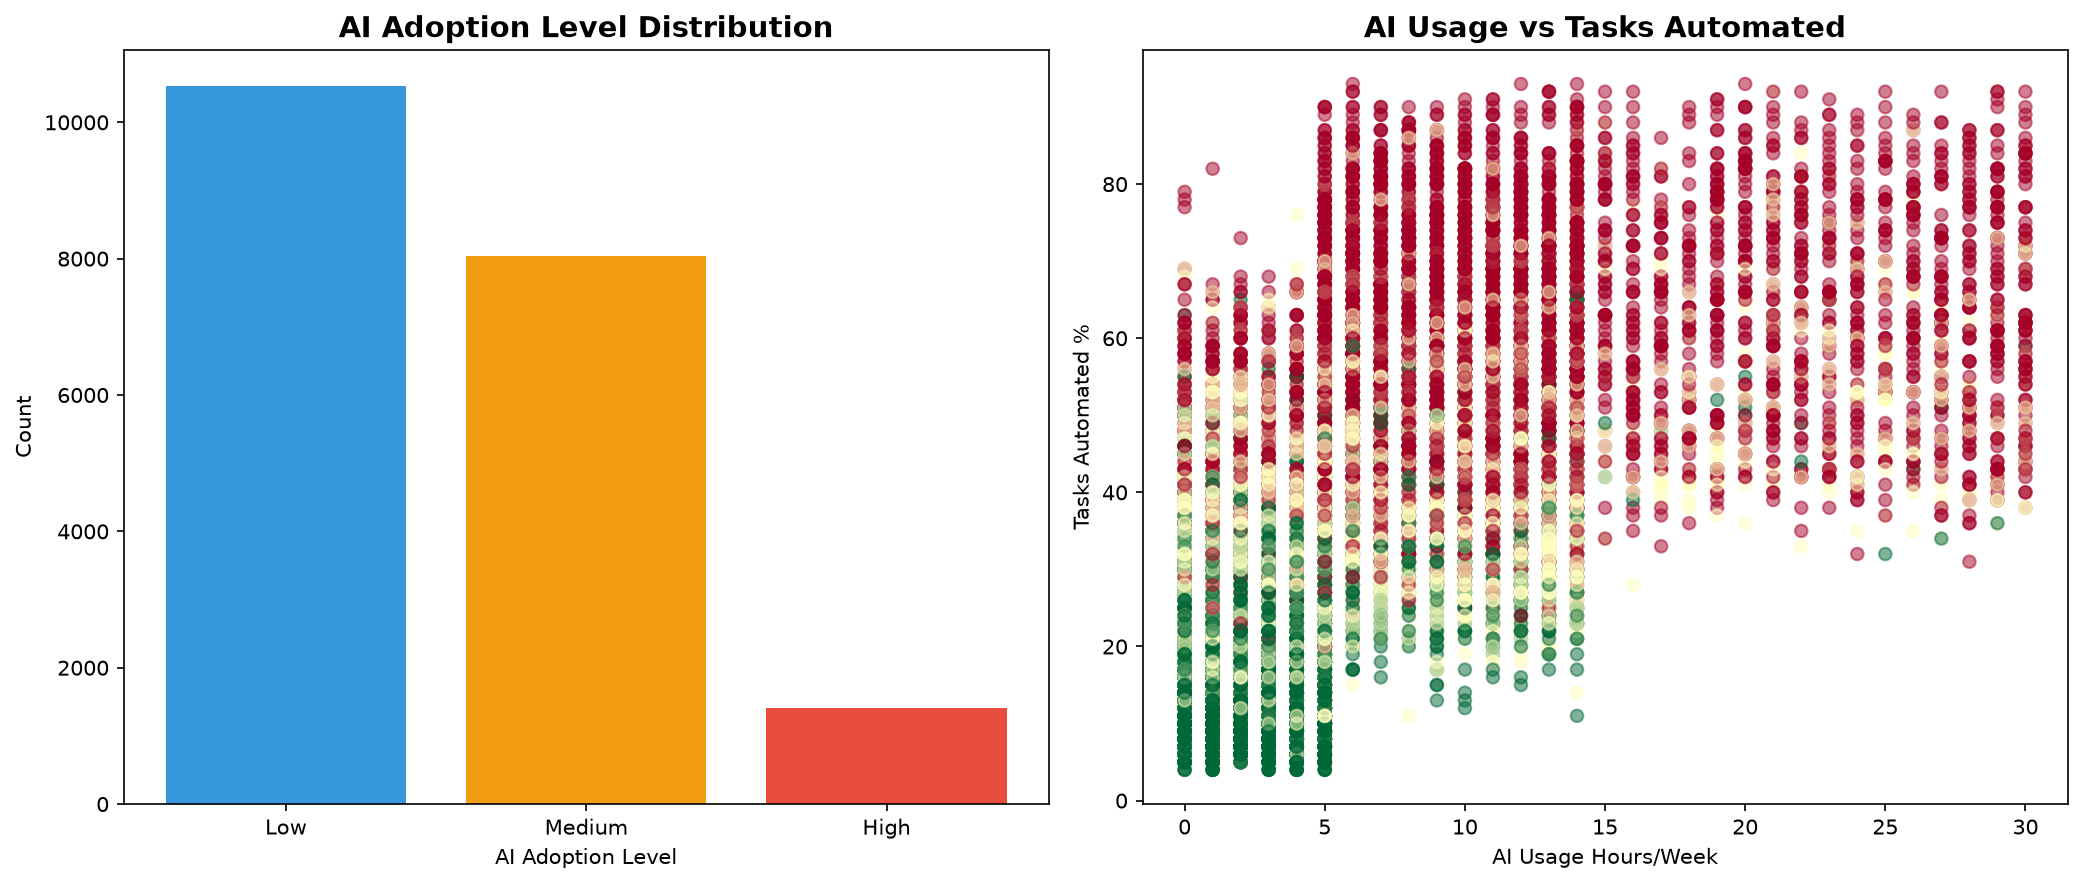

boxplots_by_risk.png


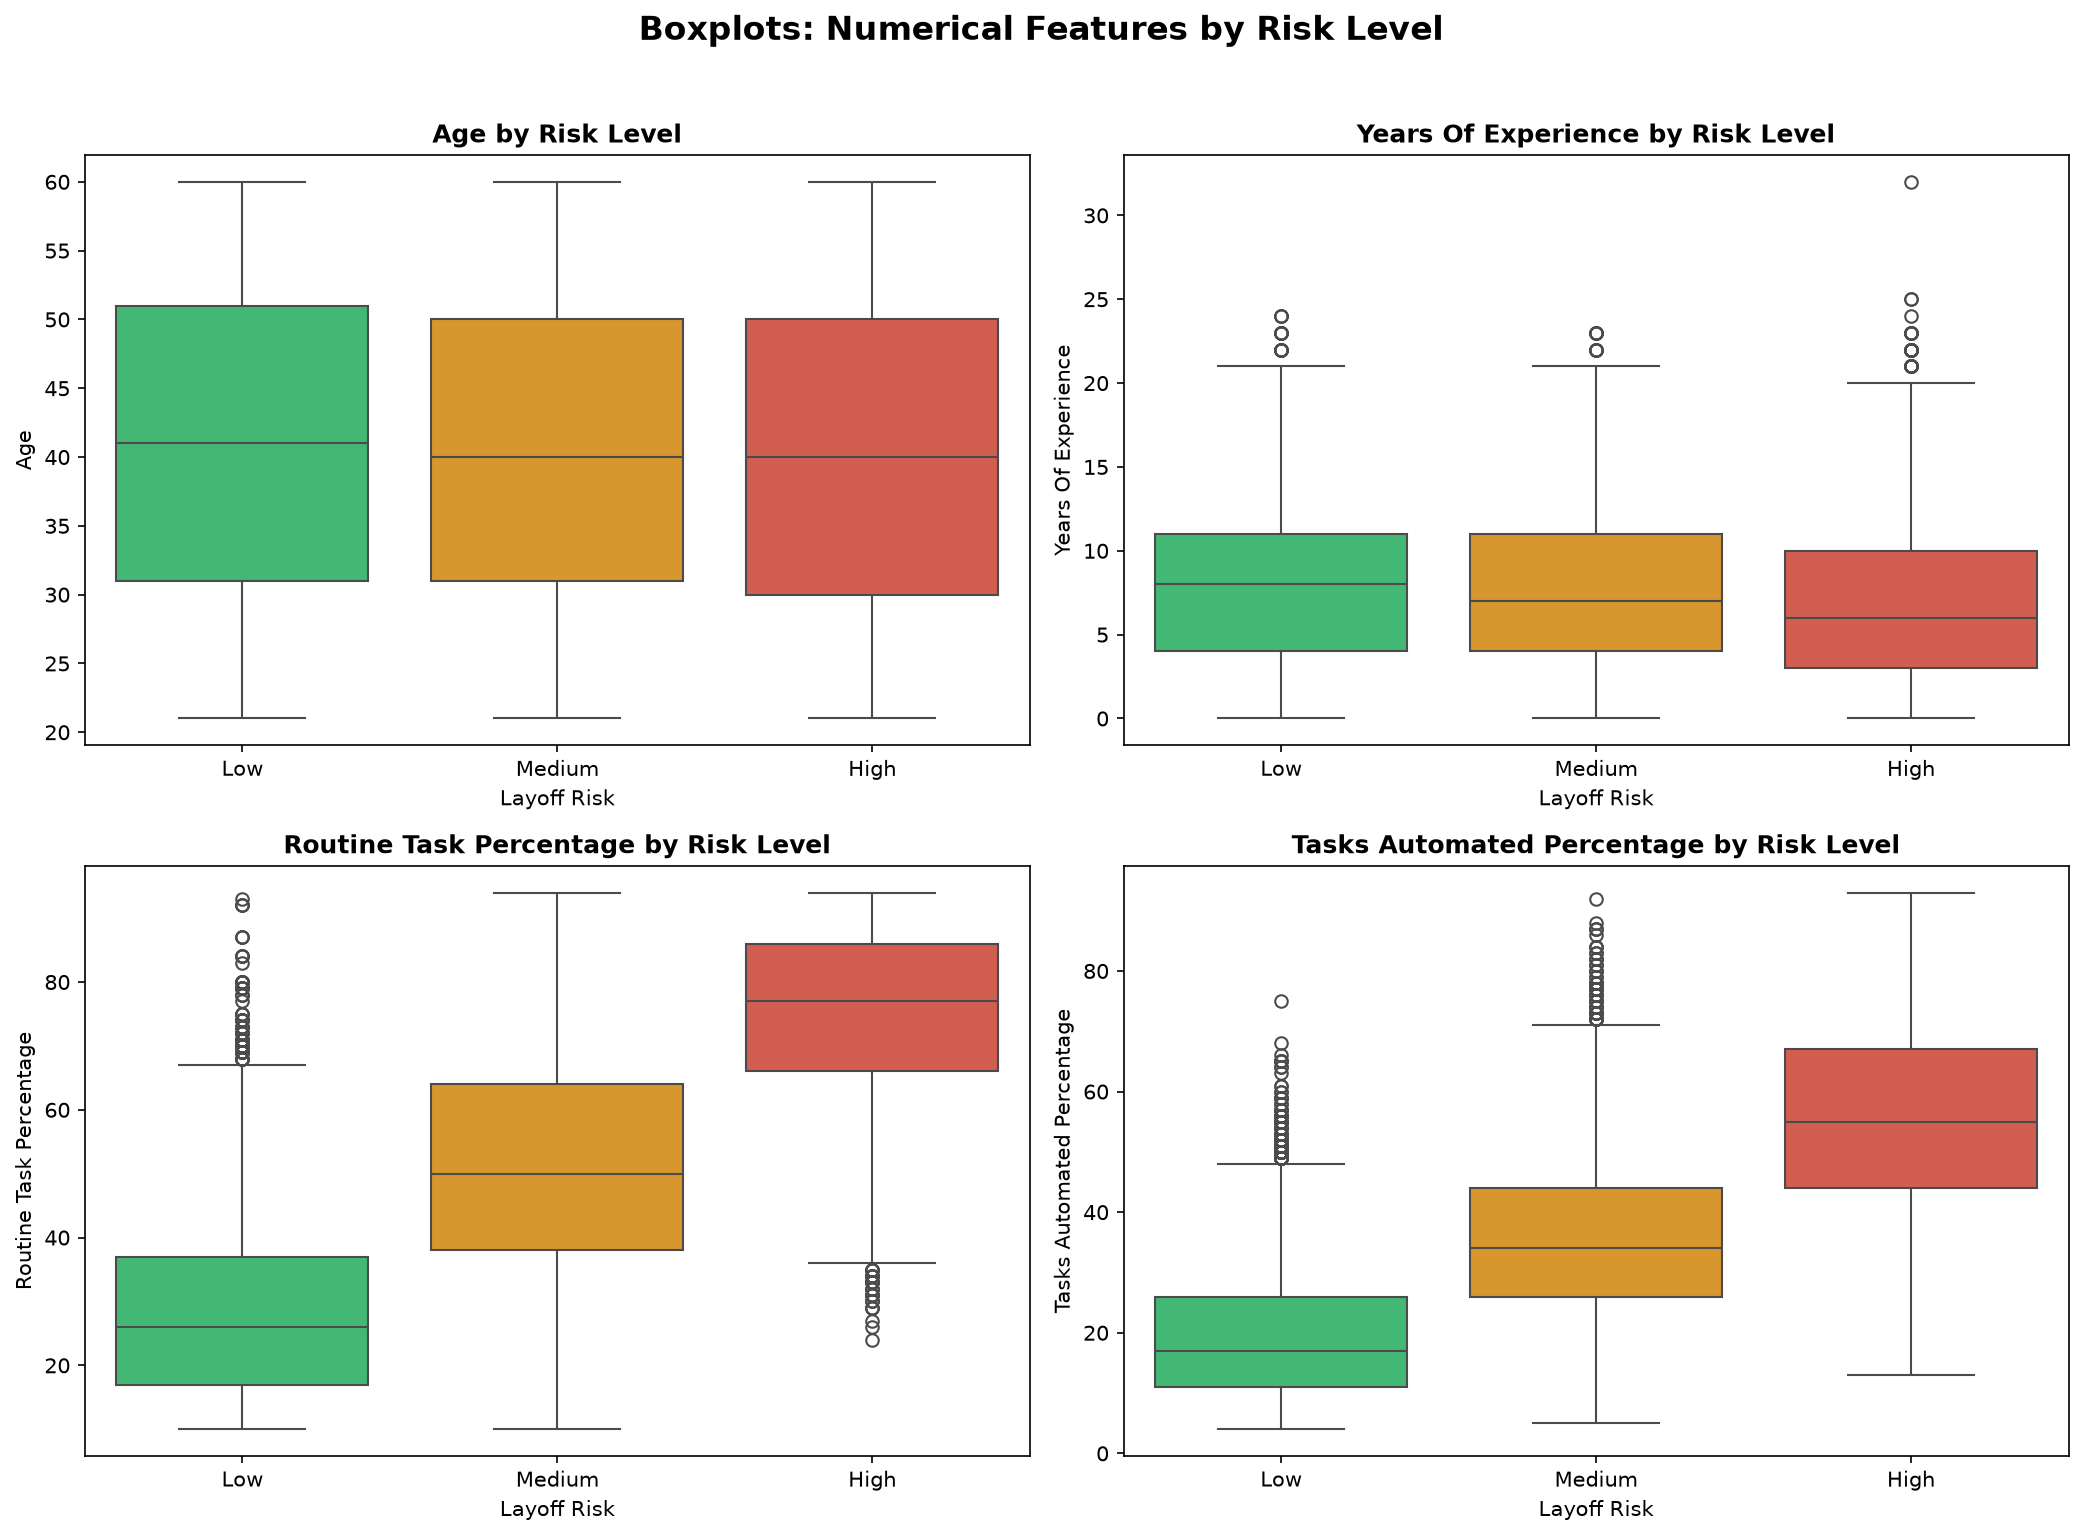

categorical_distributions.png


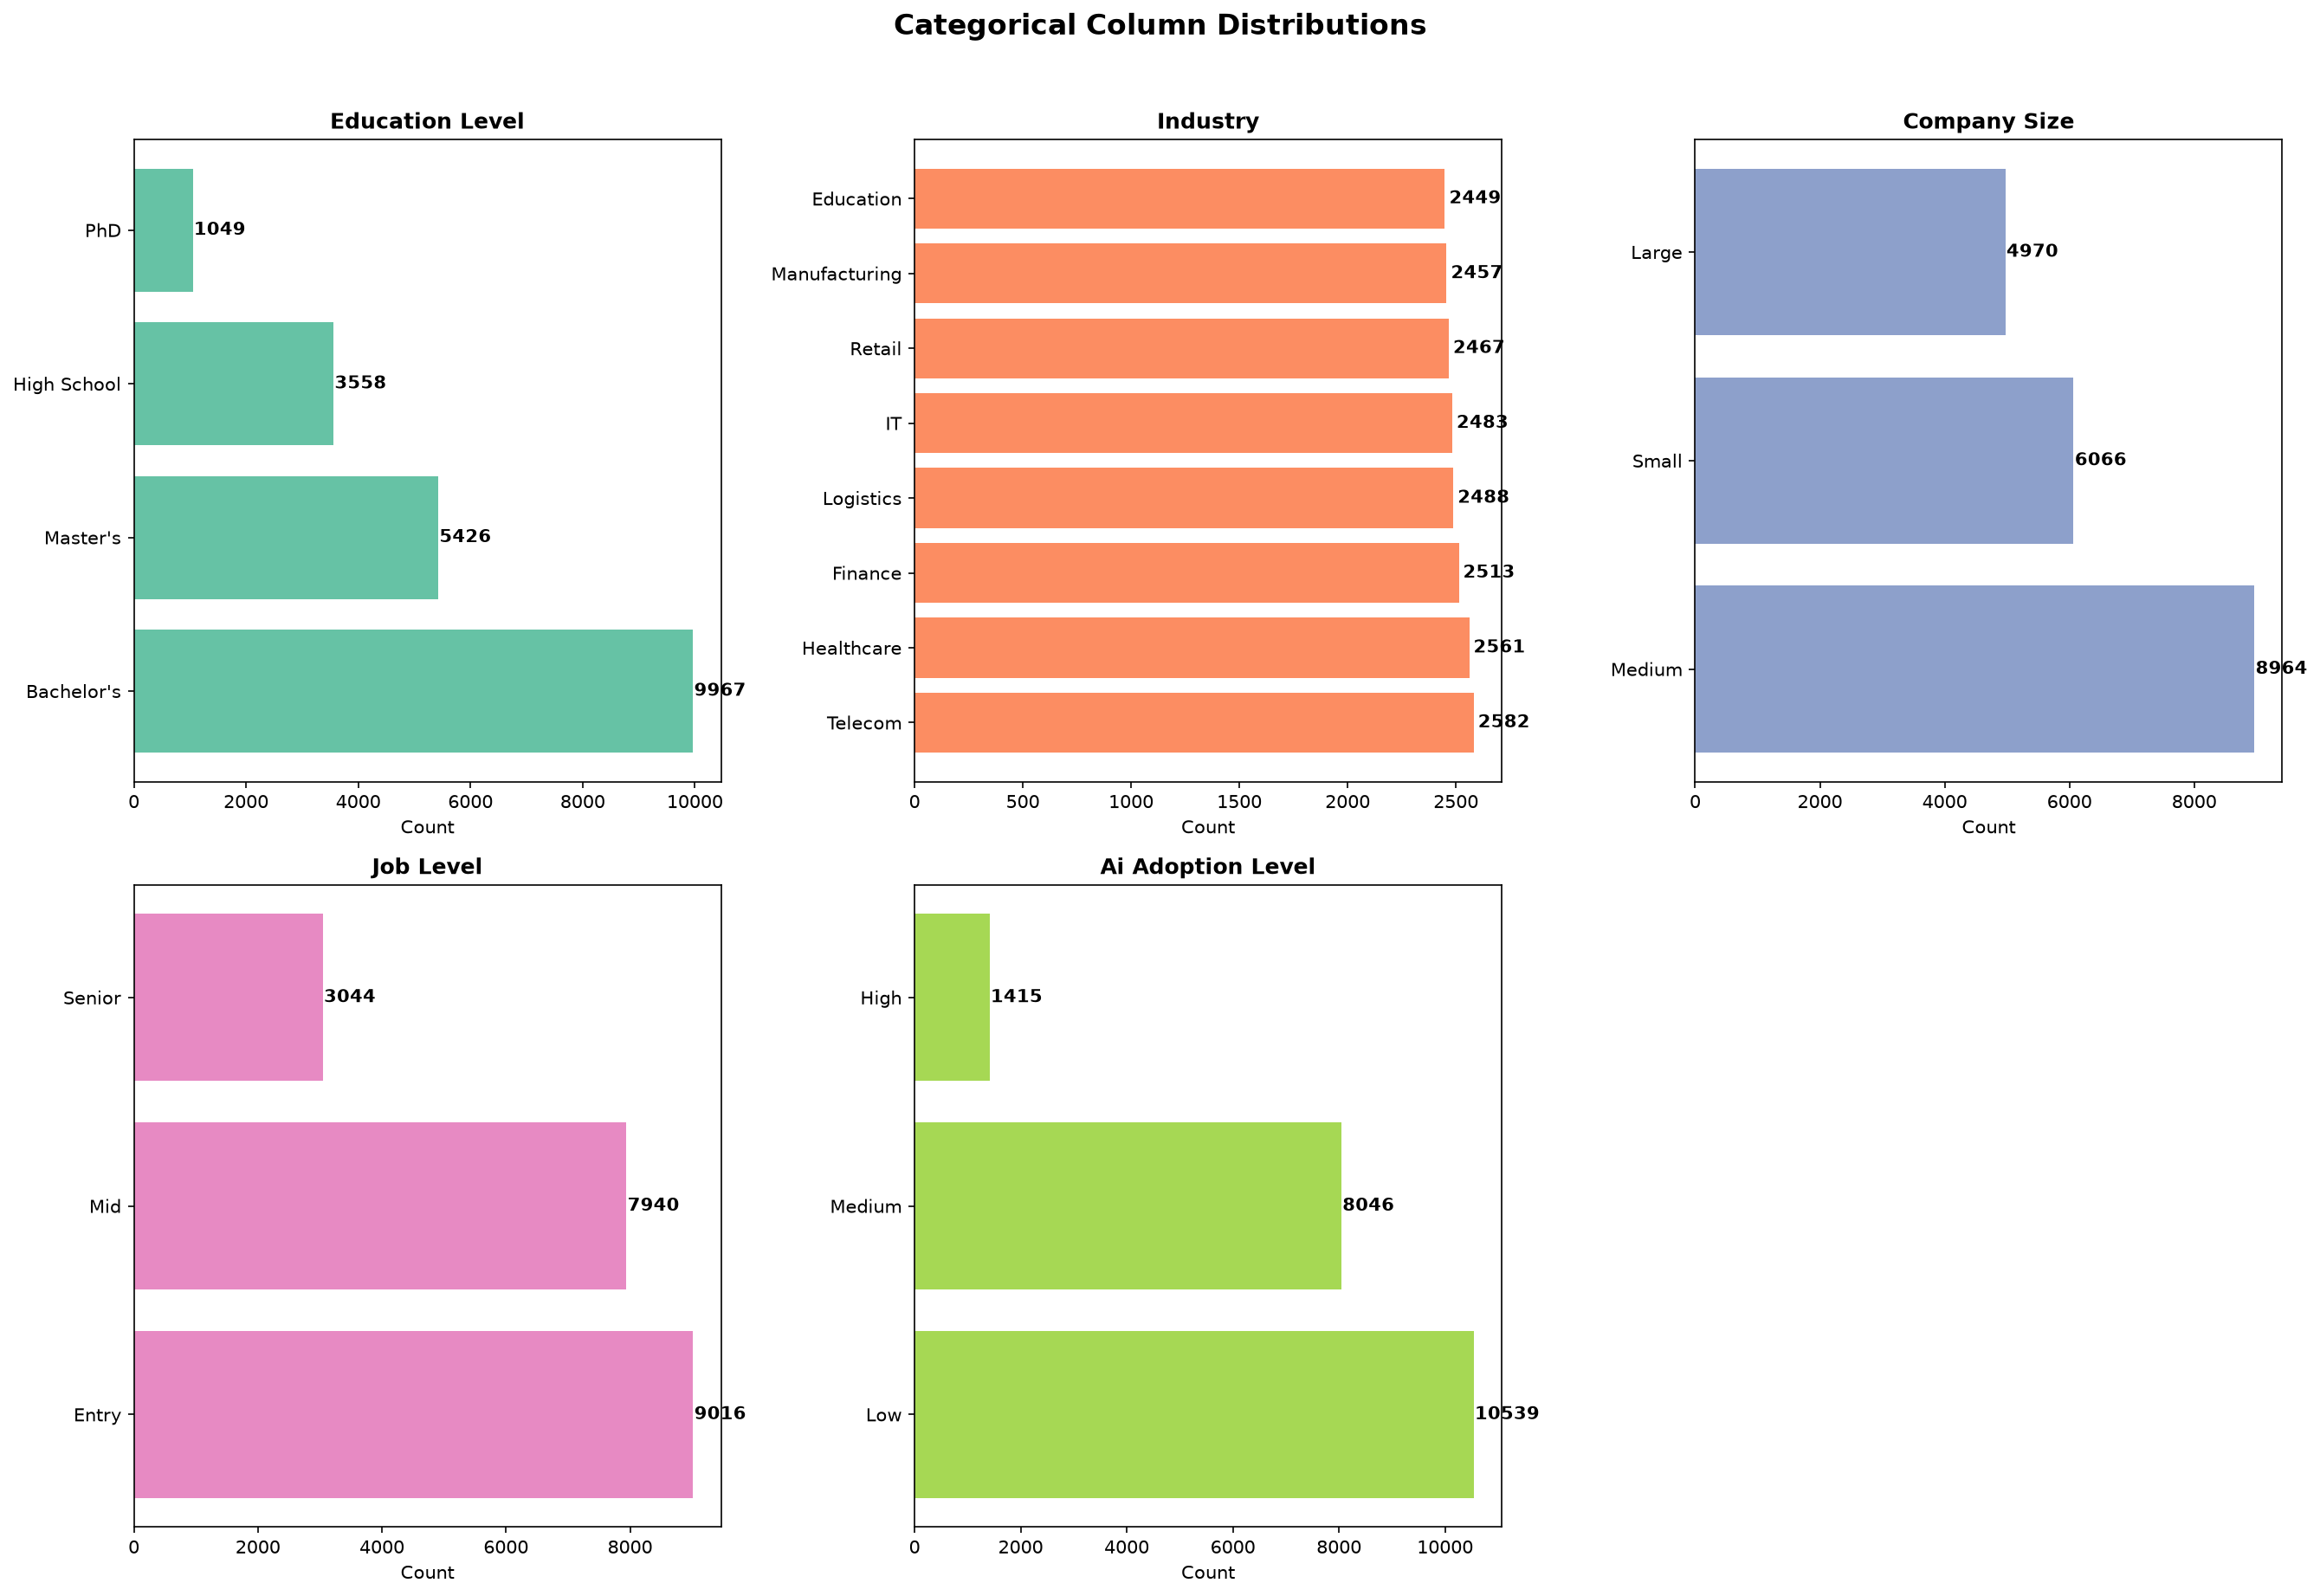

confusion_matrix_decision_tree.png


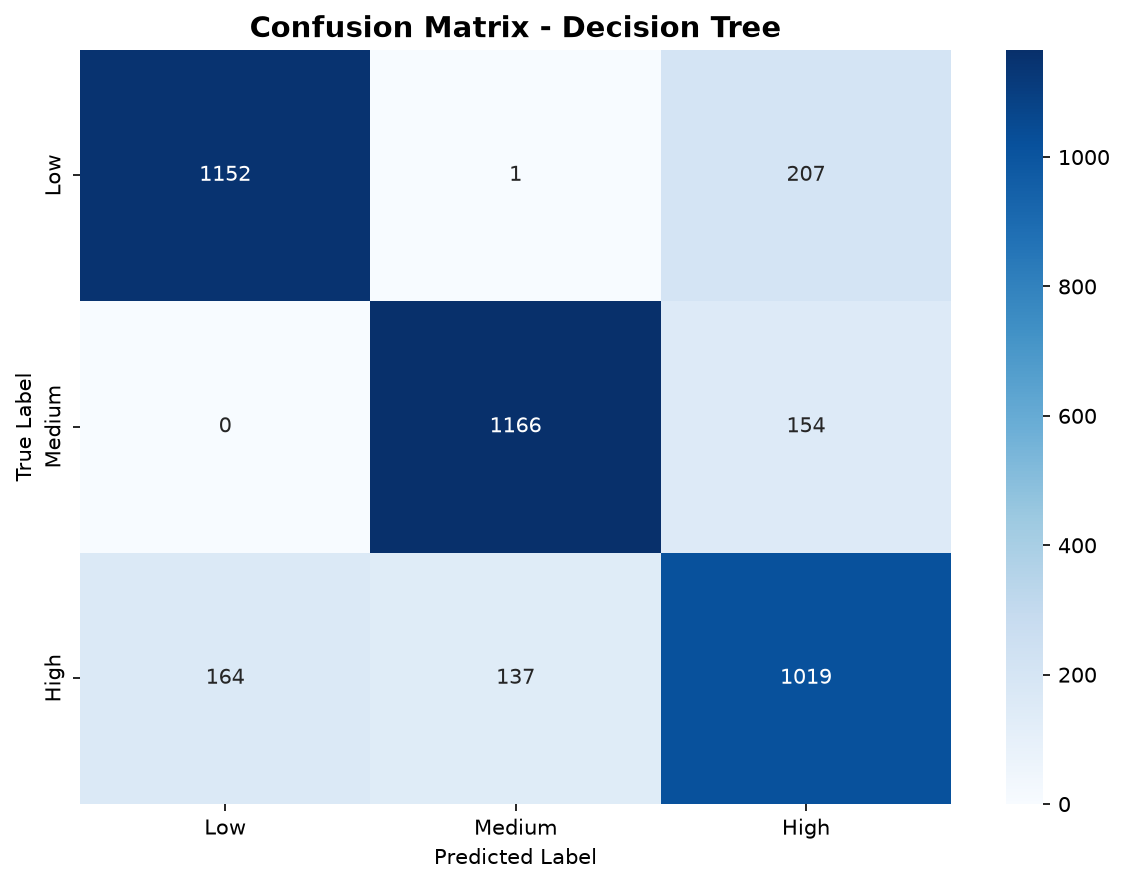

confusion_matrix_logistic_regression.png


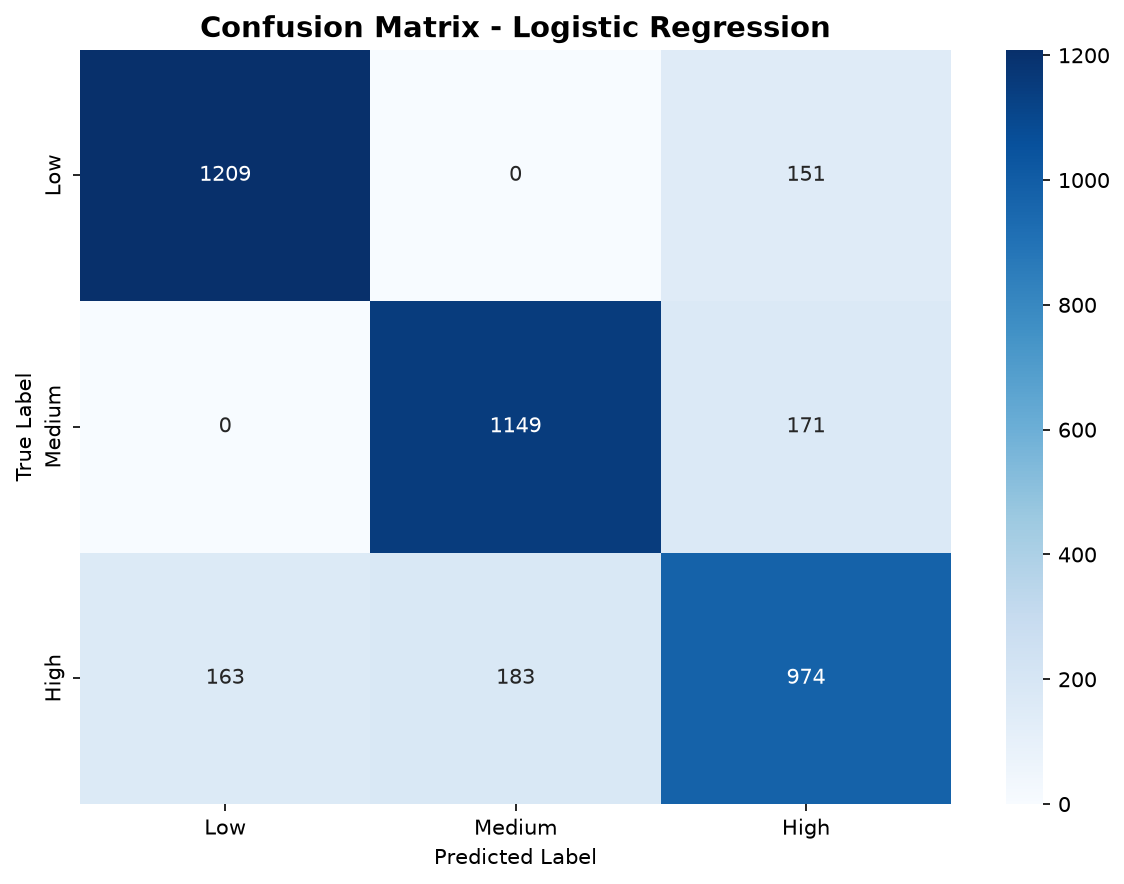

confusion_matrix_random_forest.png


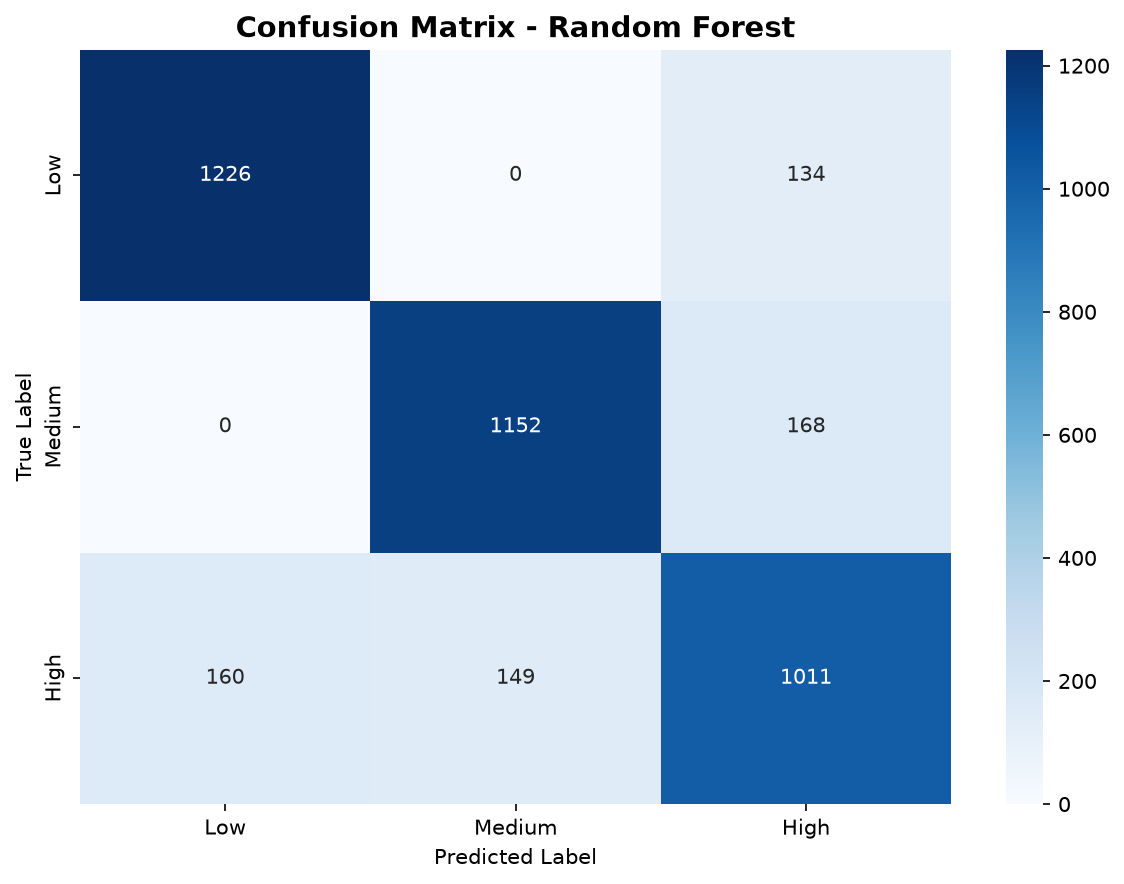

correlation_heatmap.png


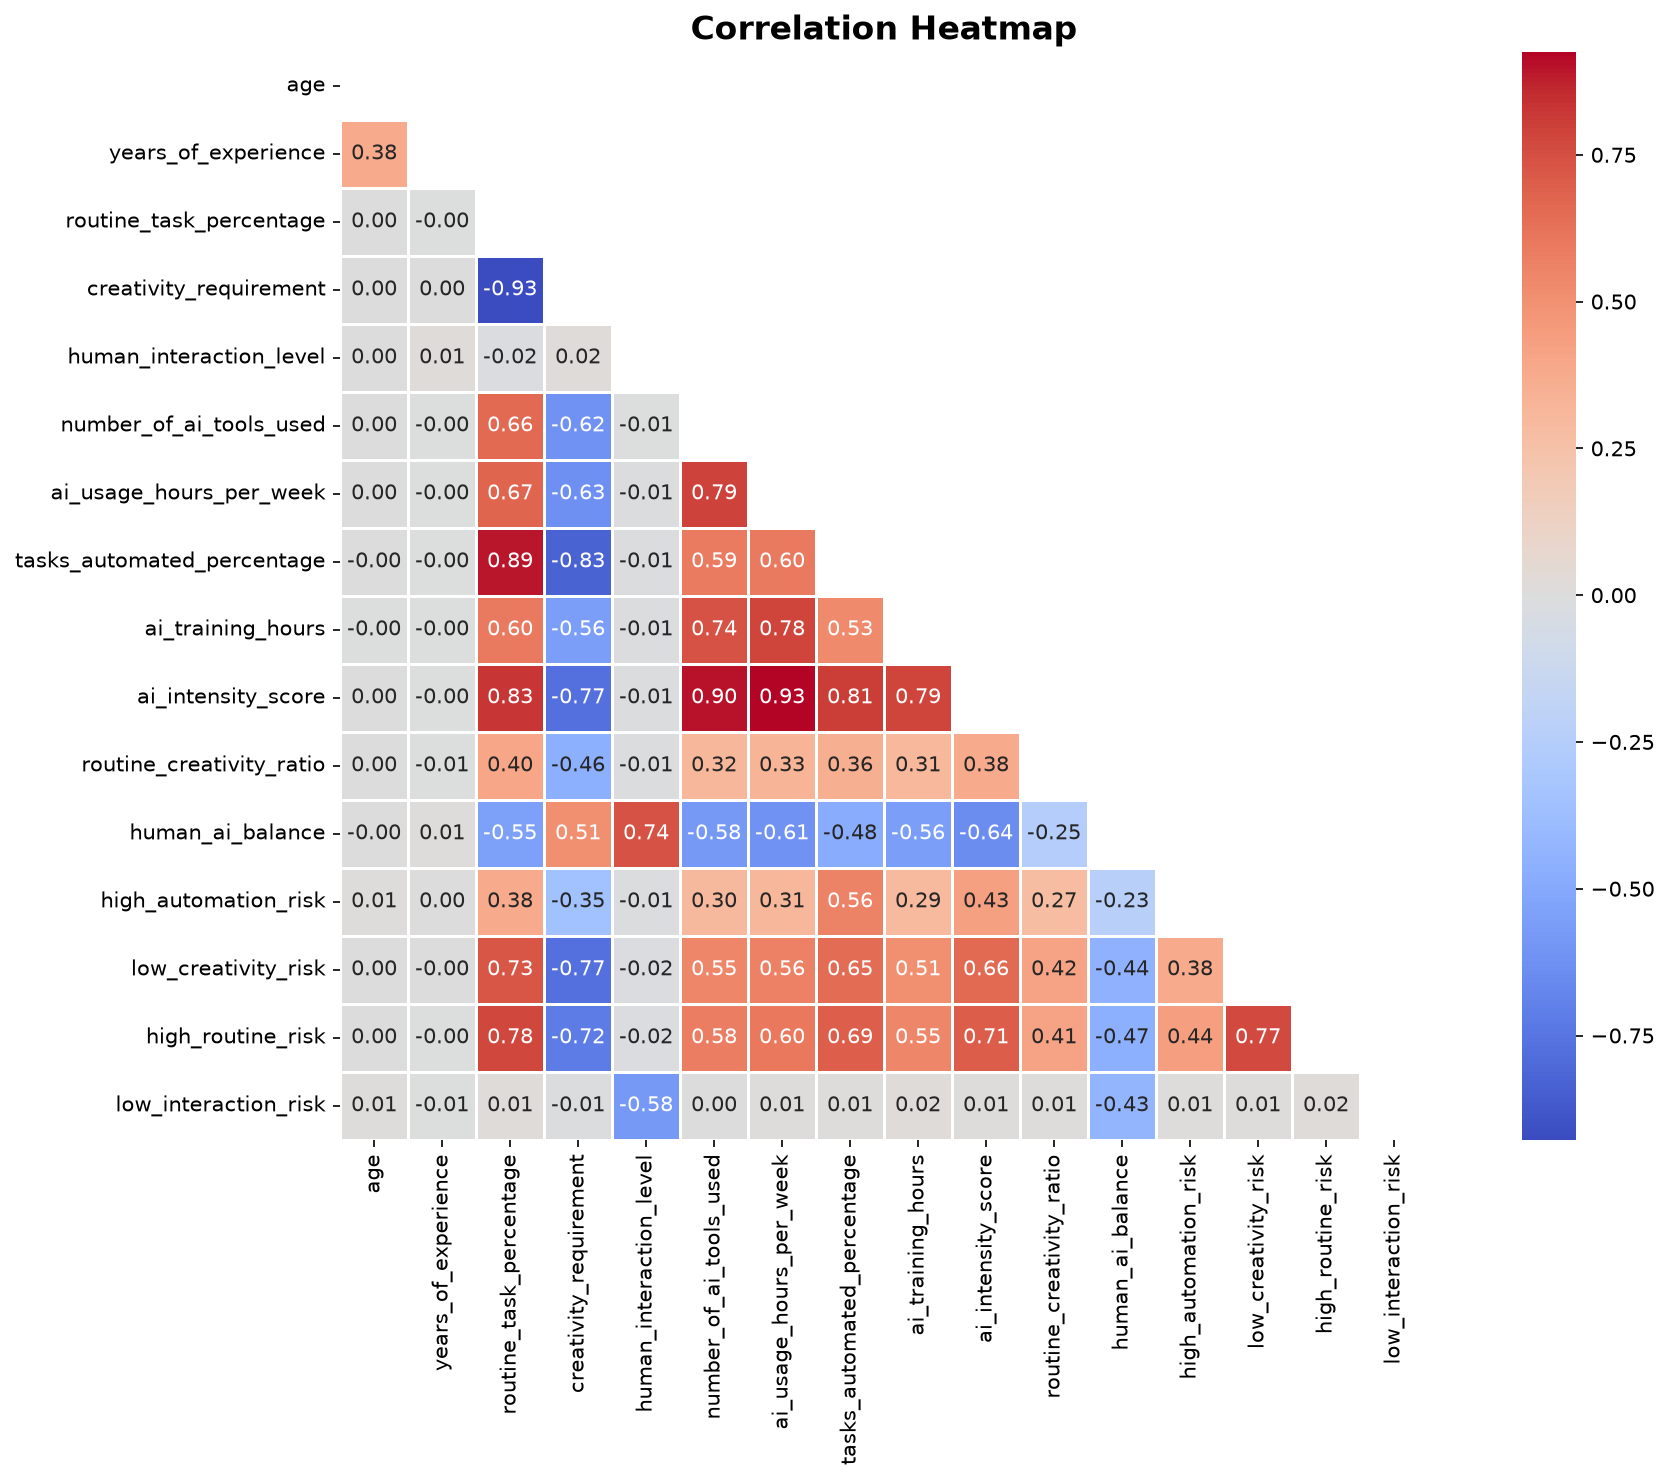

feature_importance_preview.png


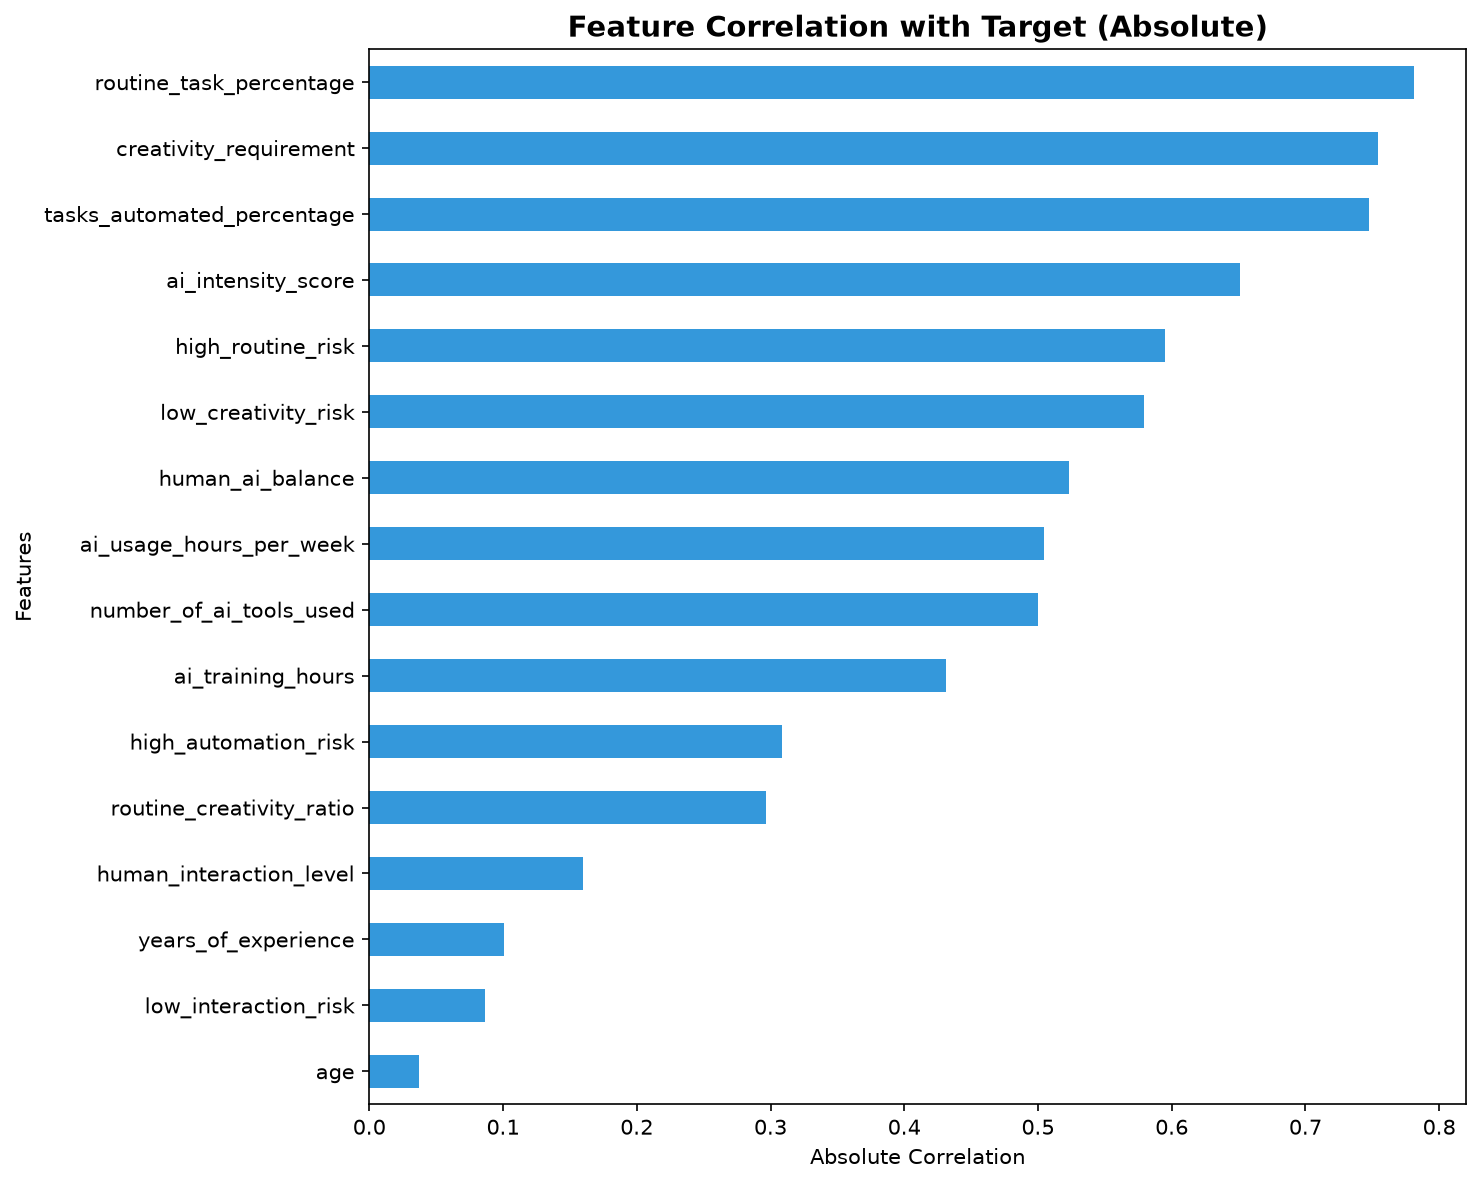

numerical_distributions.png


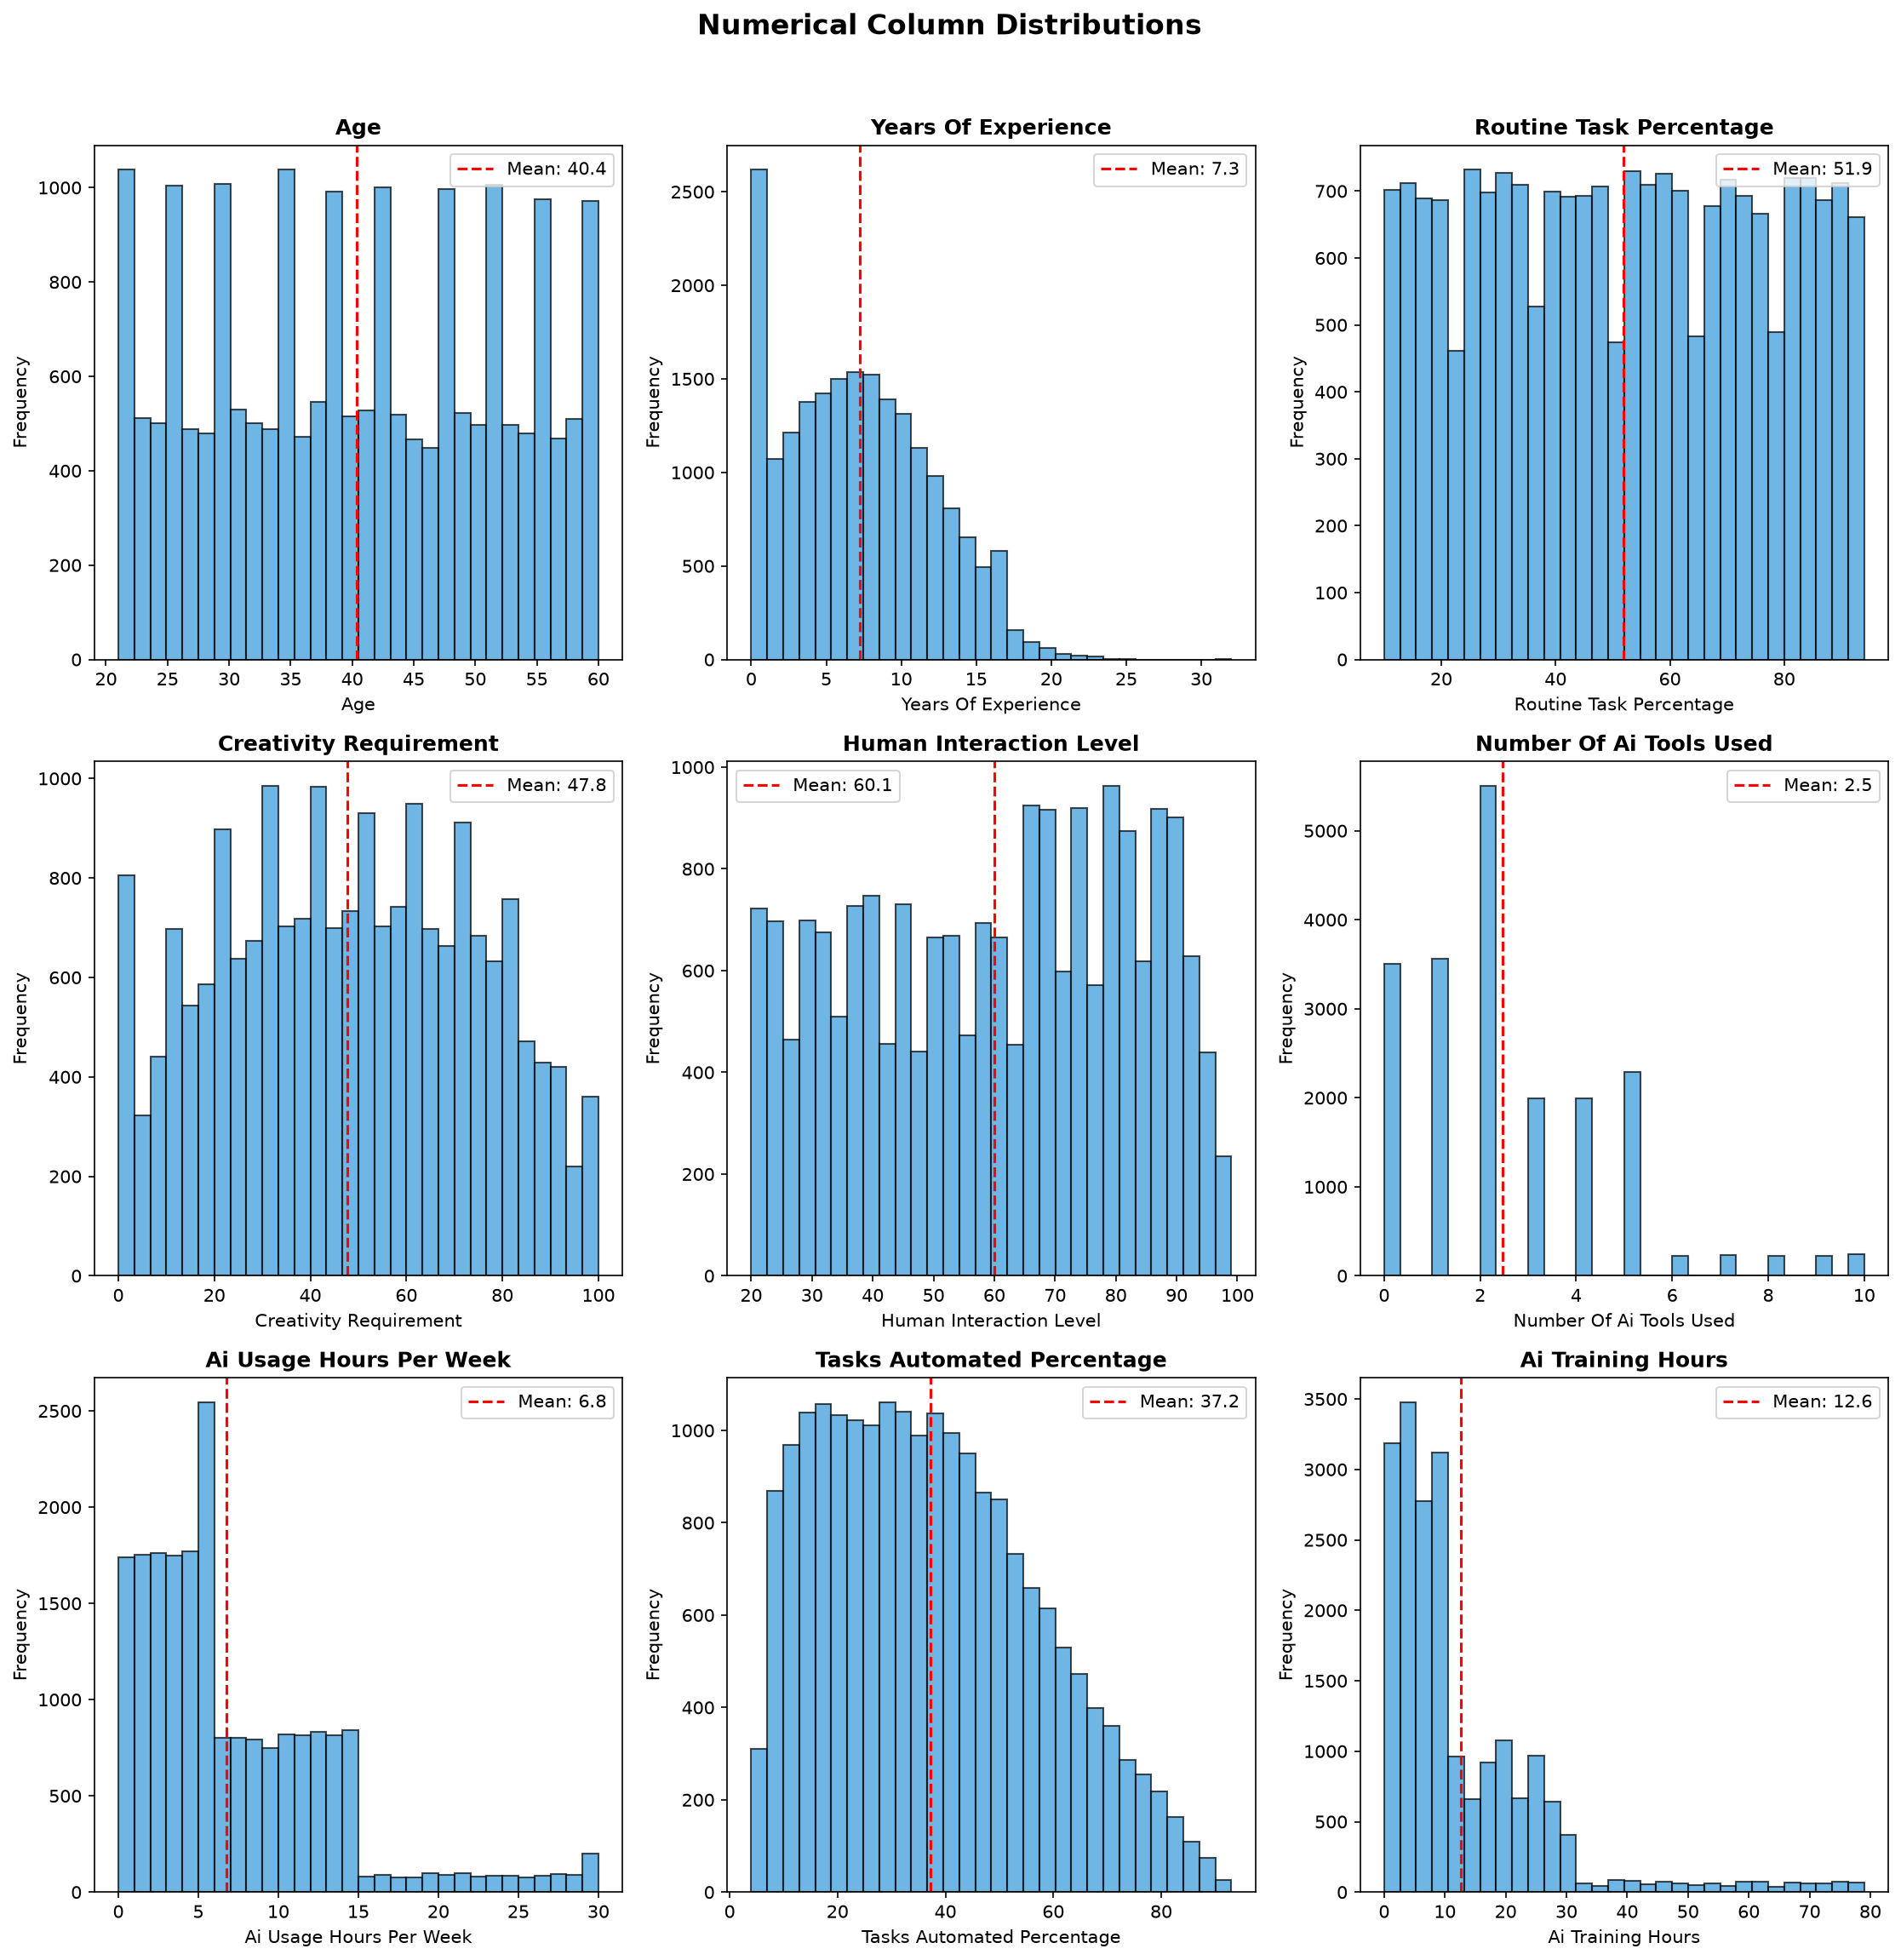

risk_by_ai_adoption_level.png


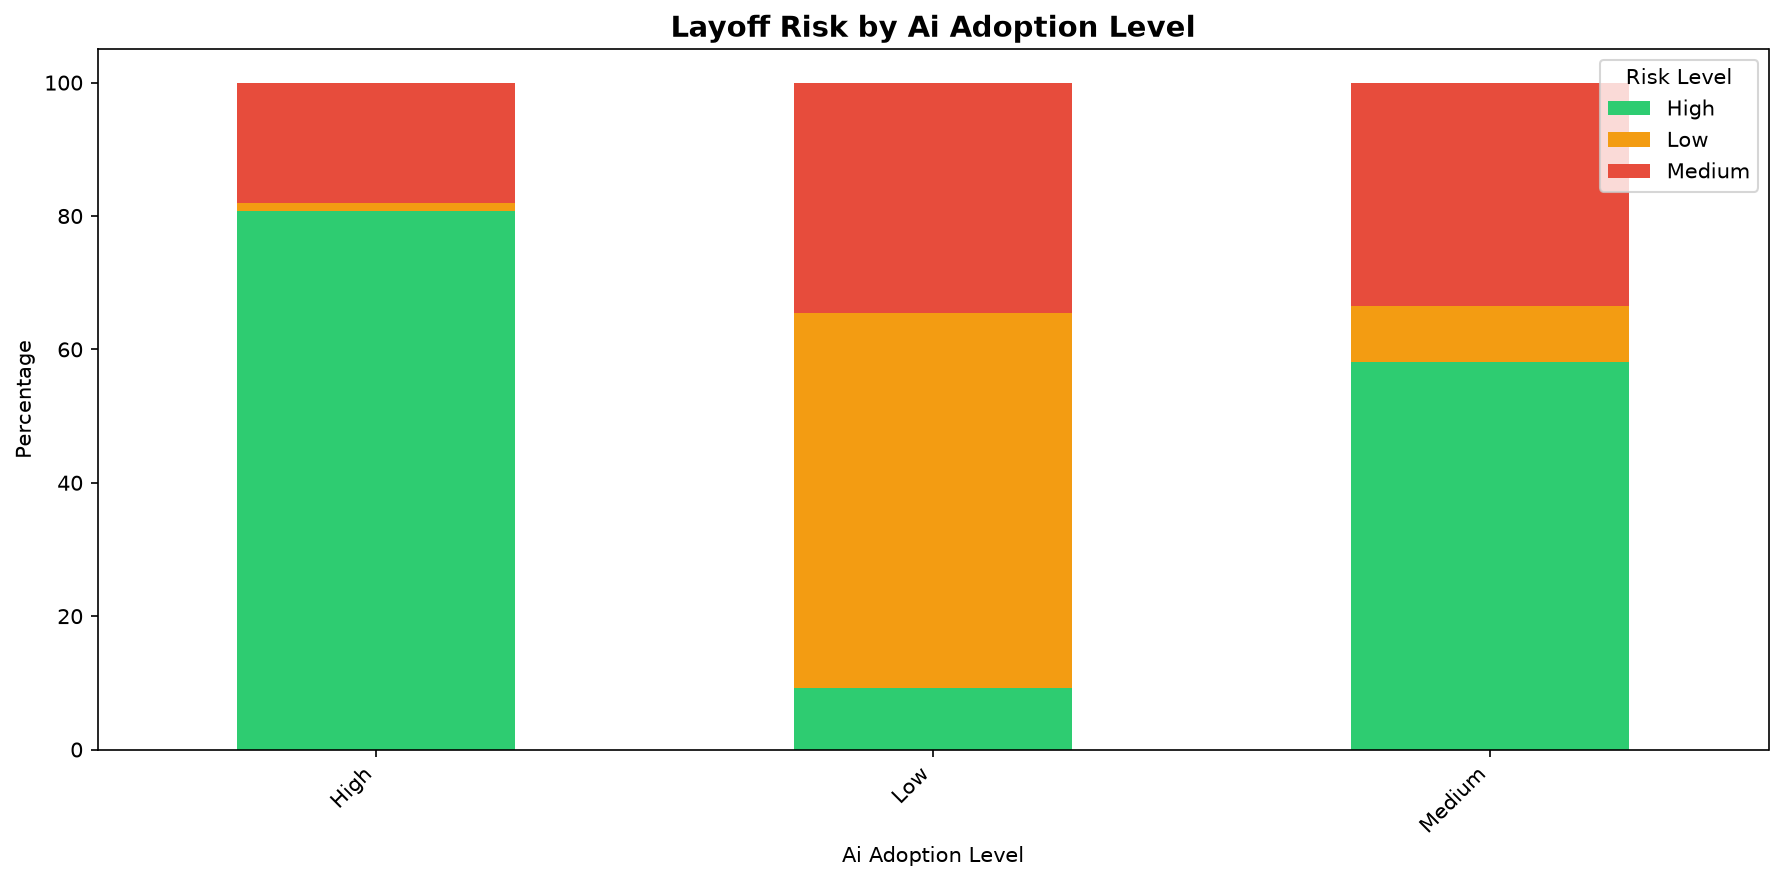

risk_by_company_size.png


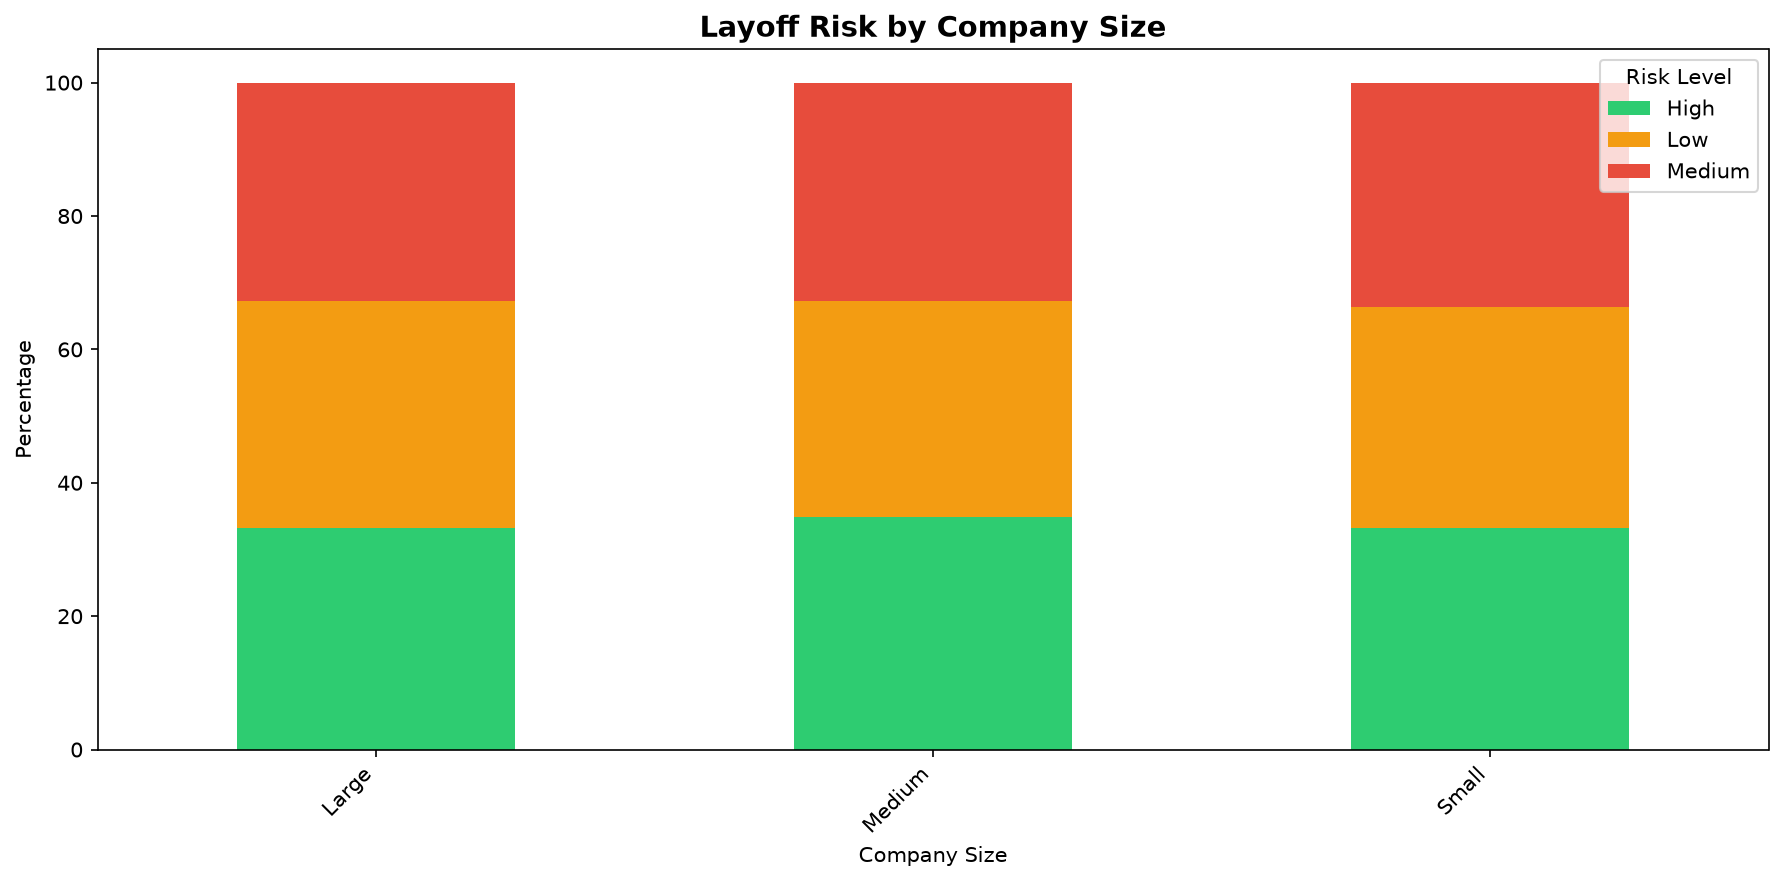

risk_by_education_level.png


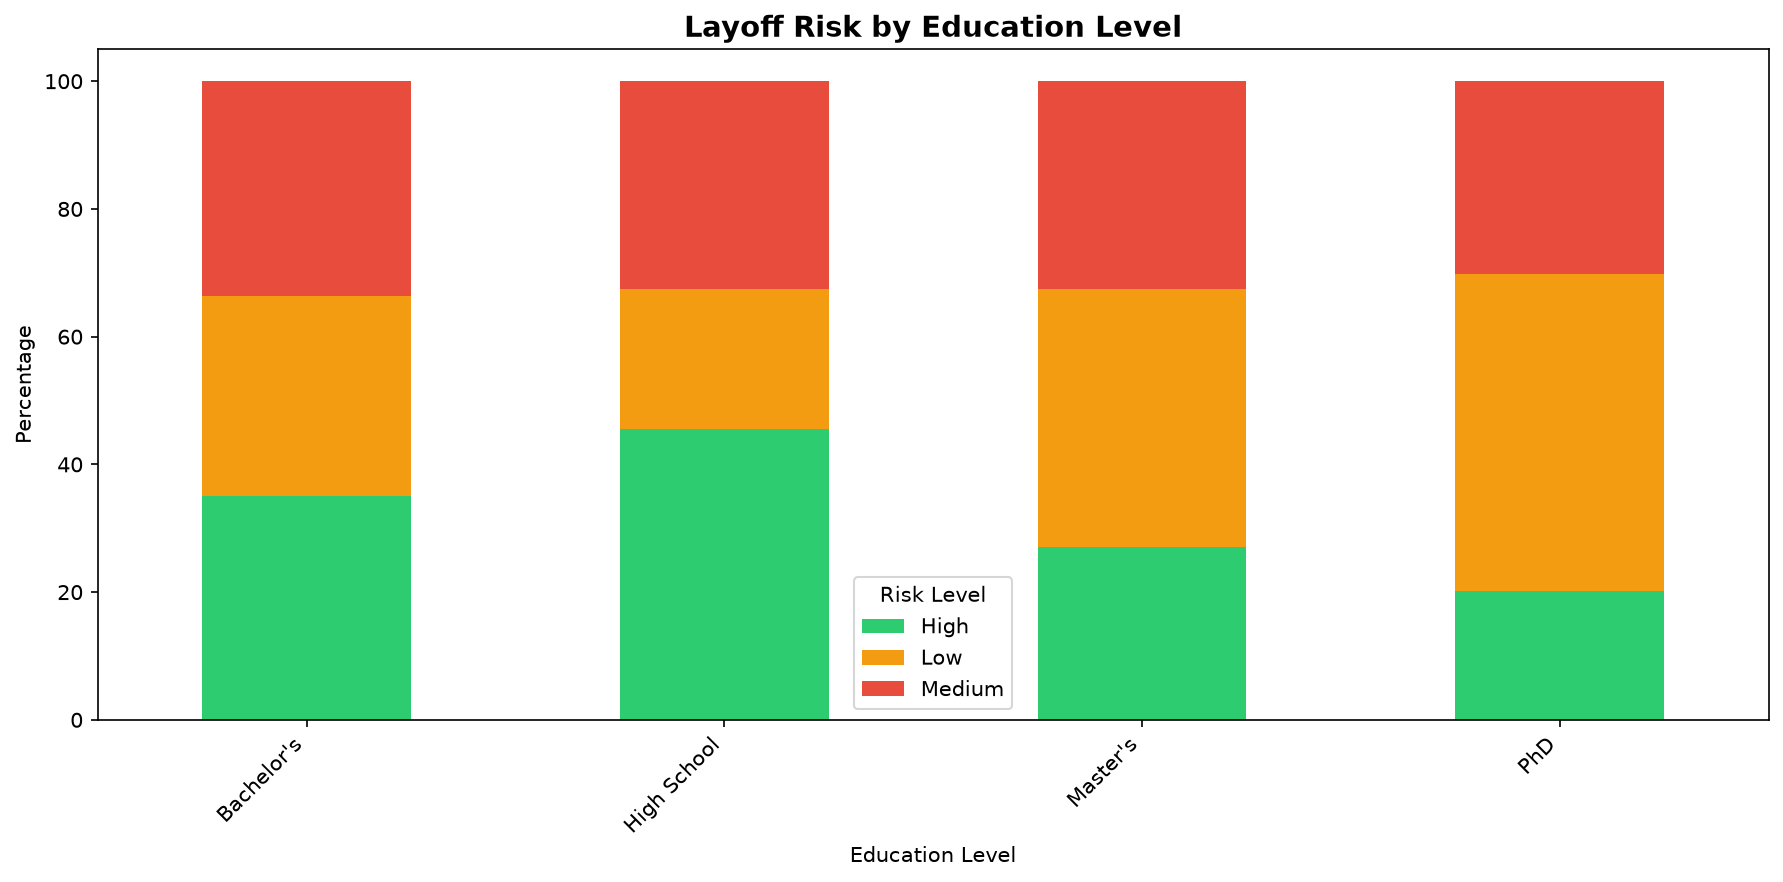

risk_by_industry.png


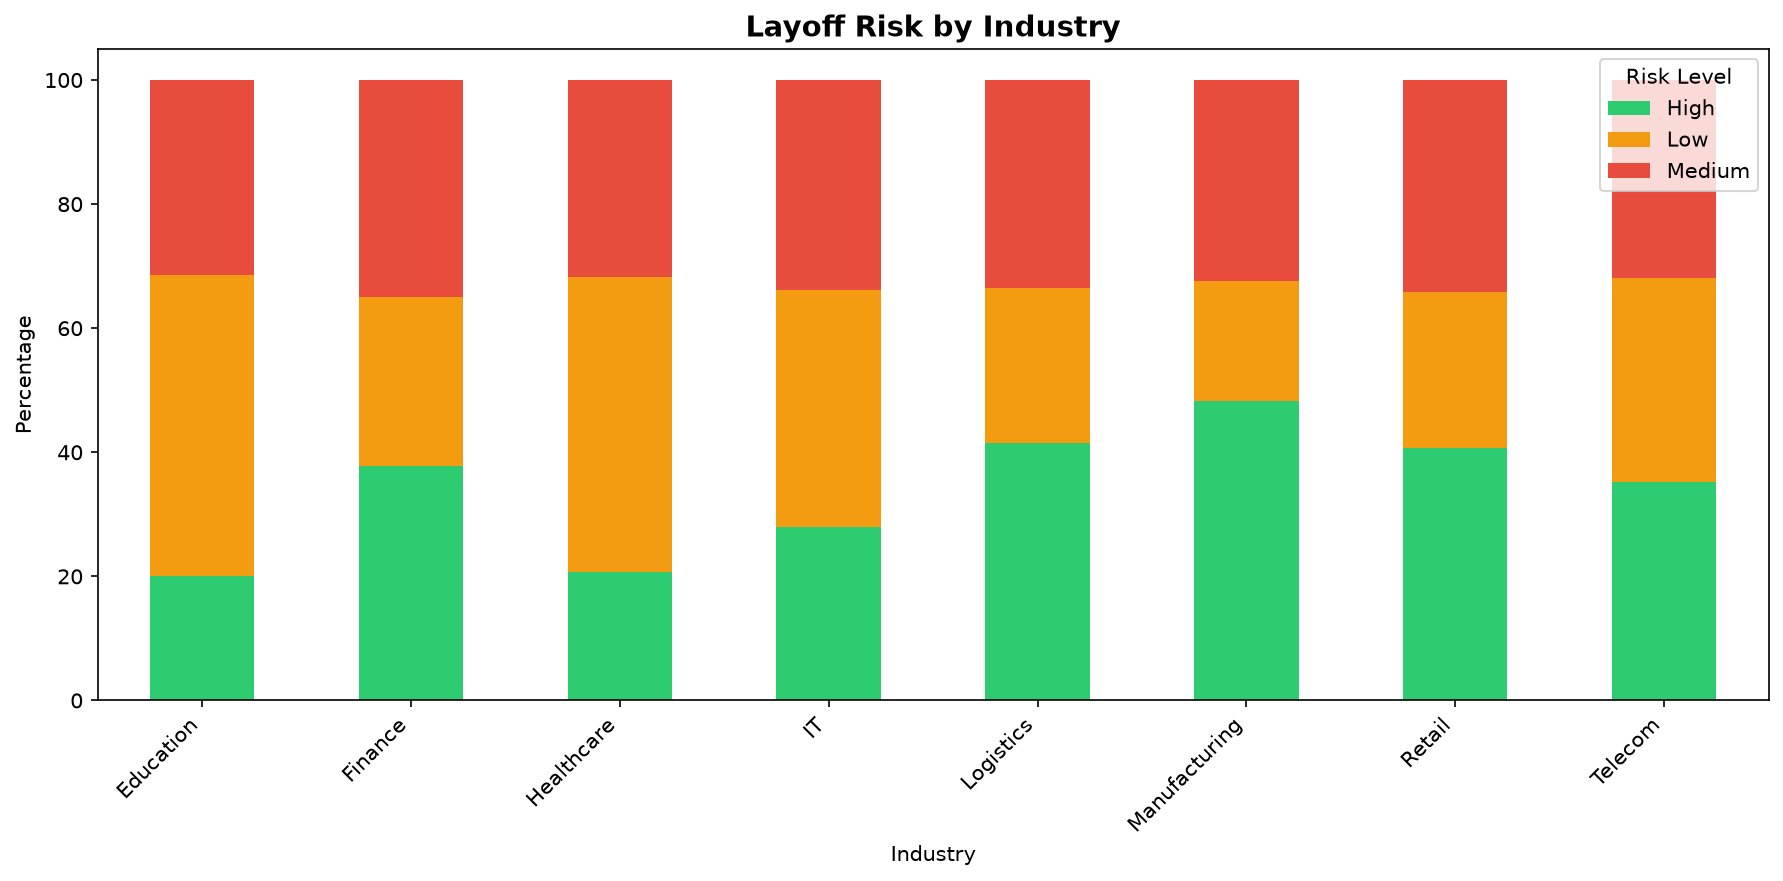

roc_curve_decision_tree.png


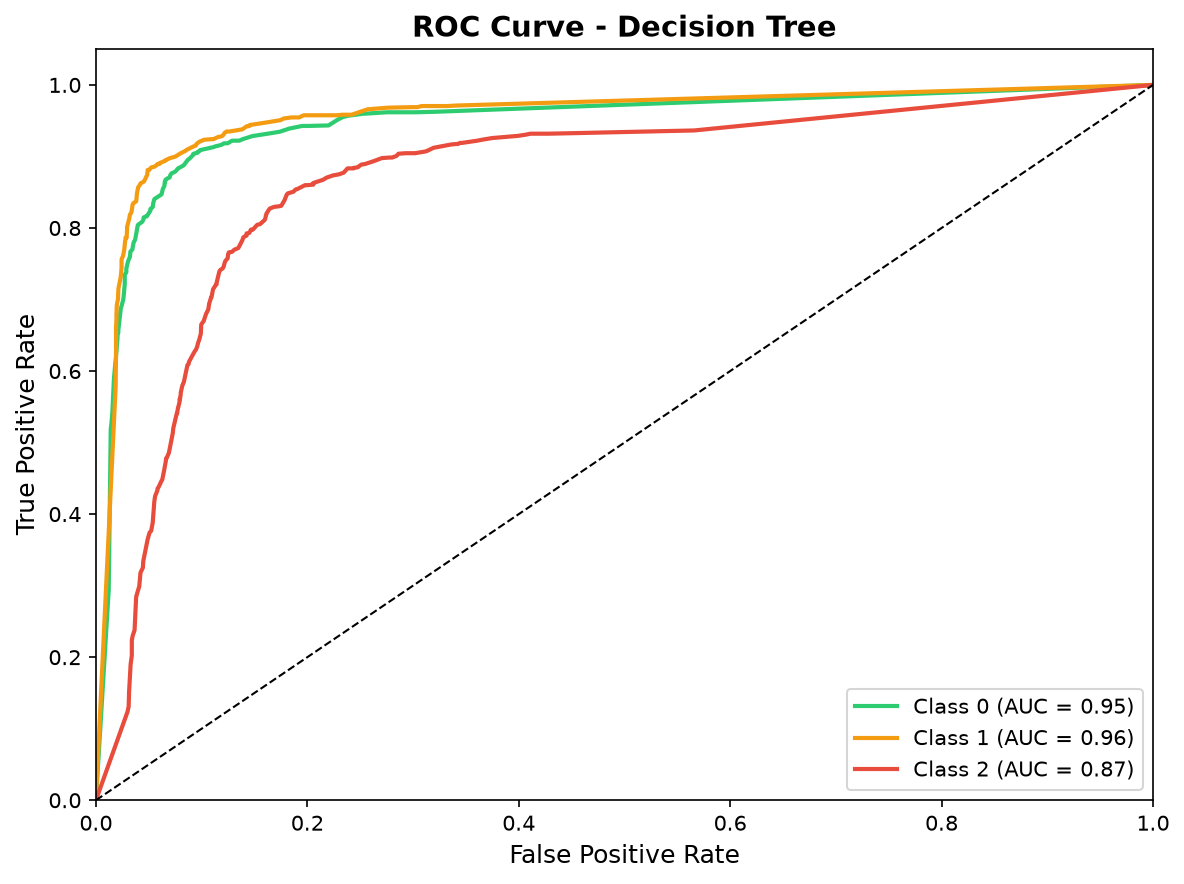

roc_curve_logistic_regression.png


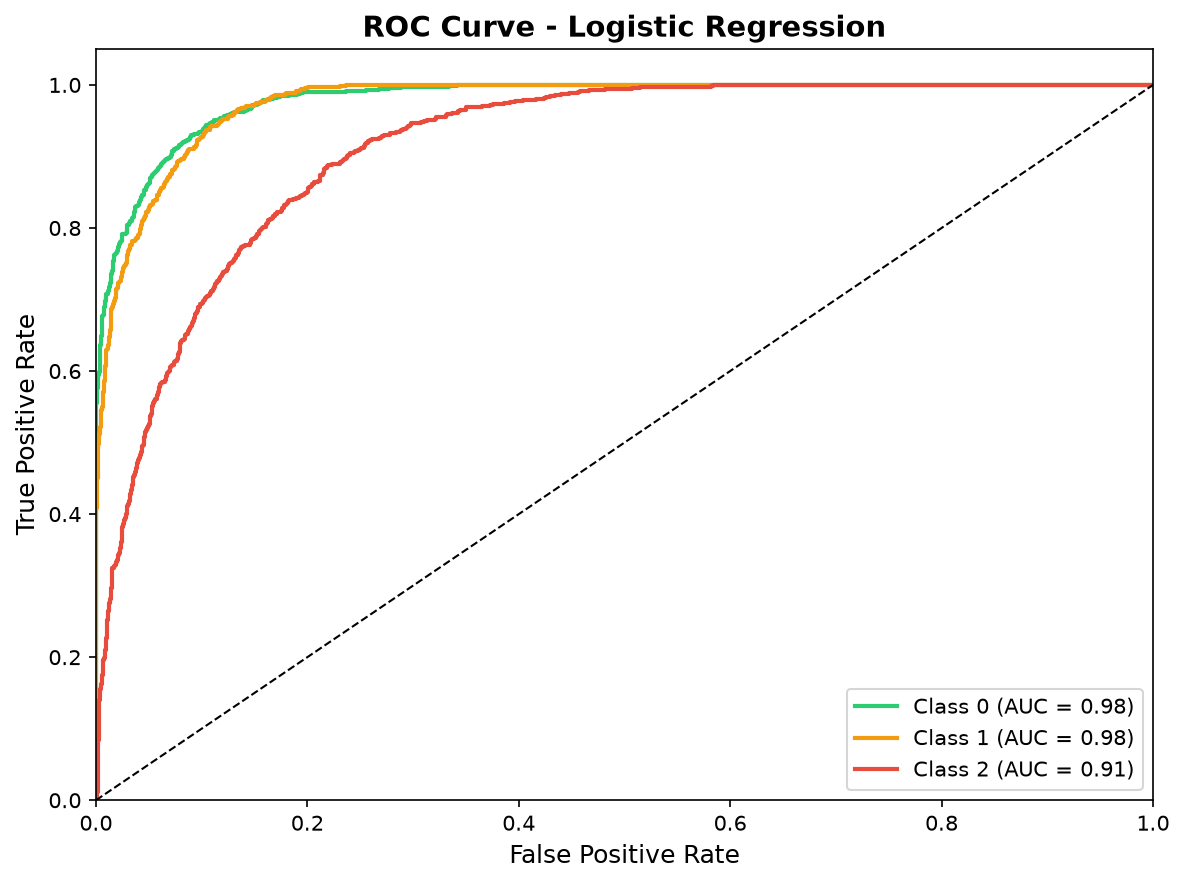

roc_curve_random_forest.png


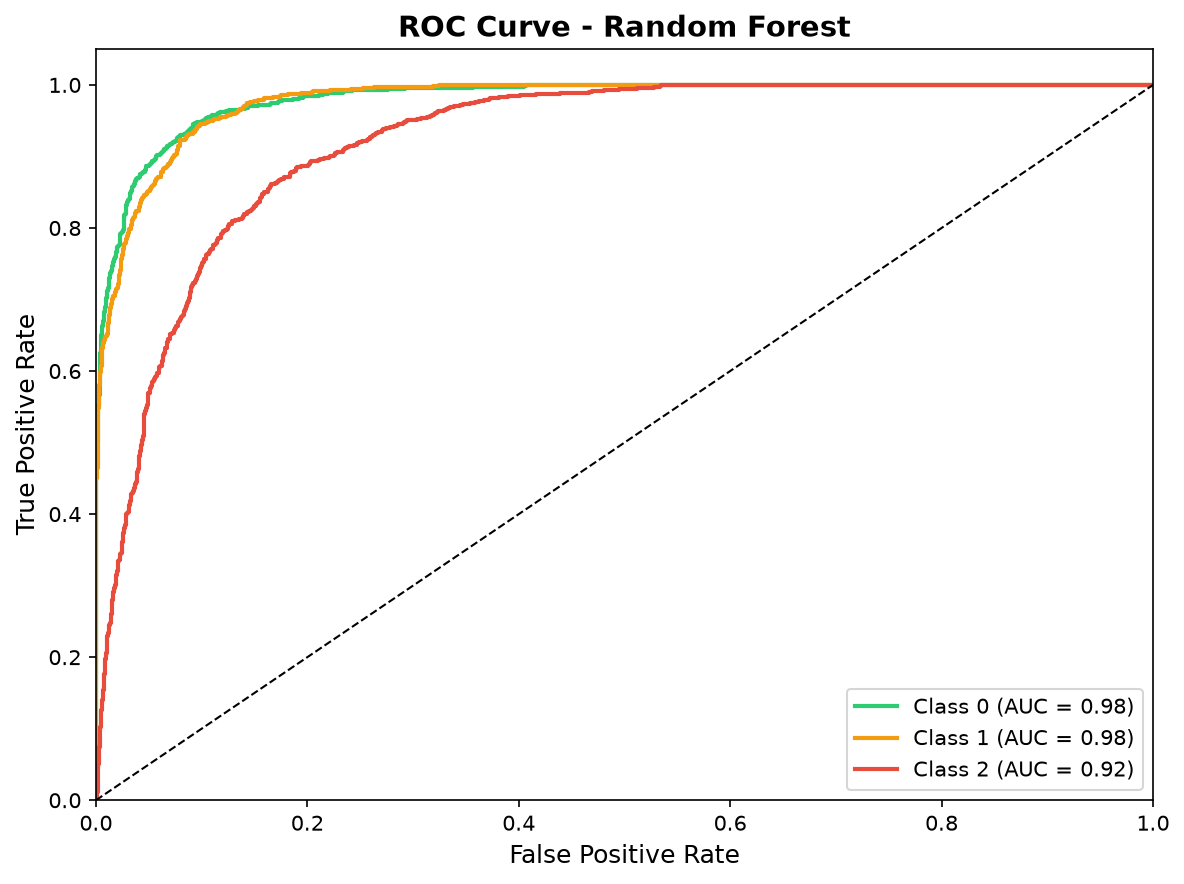

target_distribution.png


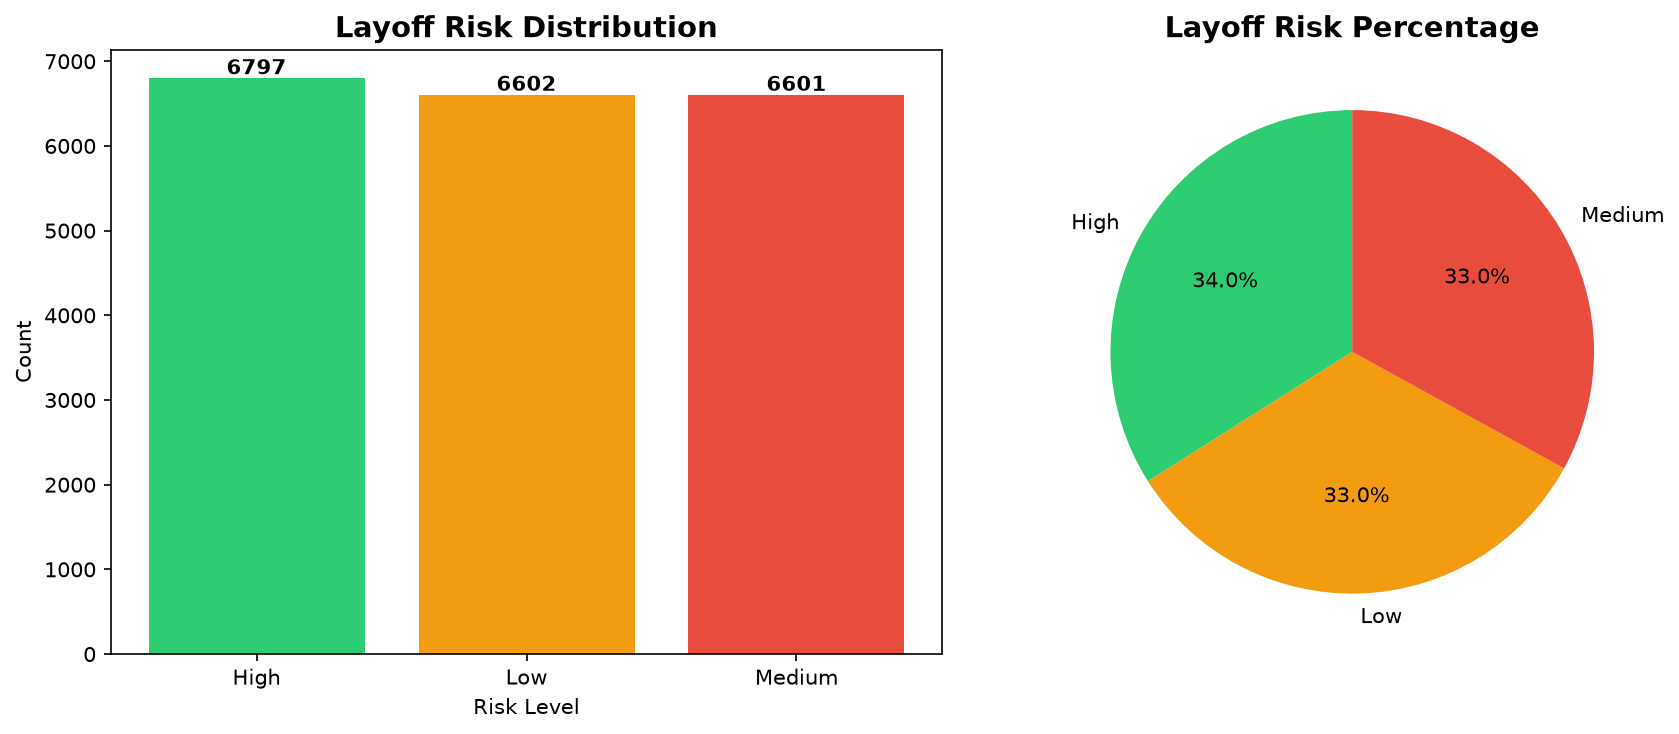

In [24]:
import sys, os
sys.path.append(os.path.abspath(".."))

from src.visualization import run_complete_visualization
from IPython.display import display, Image
import glob

run_complete_visualization(df_engineered, output_dir=config.CHARTS_OUTPUT_DIR)

for f in sorted(glob.glob(os.path.join(config.CHARTS_OUTPUT_DIR, "*.png"))):
    print(os.path.basename(f))
    display(Image(filename=f, width=750))


## Month-2: Preprocessing (Encoding + Scaling + Train/Test Split)

In [25]:
import sys, os
sys.path.append(os.path.abspath(".."))

from src.preprocessing import run_preprocessing

X_train, X_test, y_train, y_test, scaler, encoders = run_preprocessing(df_engineered, config)
print("X_train:", X_train.shape, "| X_test:", X_test.shape)


######################################################################
# DATA PREPROCESSING
######################################################################

[Preprocessing] Encoding categorical columns...
  Encoded 'education_level': 4 classes
  Encoded 'industry': 8 classes
  Encoded 'job_role': 24 classes
  Encoded 'company_size': 3 classes
  Encoded 'job_level': 3 classes
  Encoded 'ai_adoption_level': 3 classes
  Encoded 'experience_category': 4 classes
  Encoded 'age_group': 5 classes
  Encoded target 'layoff_risk': ['High', 'Low', 'Medium']

Total columns encoded: 9

[Preprocessing] Splitting features and target...
  Features shape: (20000, 24)
  Target shape: (20000,)
  Target distribution:
layoff_risk
0    6797
1    6602
2    6601
Name: count, dtype: int64

[Preprocessing] Scaling numerical columns...
  Scaled 24 numerical columns
  Columns: age, education_level, years_of_experience, industry, job_role, company_size, job_level, routine_task_percentage, creativity_requir

## Month-3: Model Training

In [26]:
import sys, os
sys.path.append(os.path.abspath(".."))

from src.model_training import run_model_training

trained_models, comparison_df, best_model_name = run_model_training(
    X_train, X_test, y_train, y_test, config
)
comparison_df


######################################################################
# MODEL TRAINING
######################################################################

[Model Training] Initializing models...
  - Logistic Regression: Initialized
  - Decision Tree: Initialized
  - Random Forest: Initialized

TRAINING ALL MODELS

  Training Logistic Regression...
  Logistic Regression trained in 0.32 seconds
  Logistic Regression - Training Accuracy: 0.8343

  Training Decision Tree...
  Decision Tree trained in 0.12 seconds
  Decision Tree - Training Accuracy: 0.9224

  Training Random Forest...
  Random Forest trained in 0.73 seconds
  Random Forest - Training Accuracy: 0.9201

Successfully trained: 3/3 models

MODEL COMPARISON

              Model Training Time (s) Train Accuracy Test Accuracy
Logistic Regression              0.32         0.8343        0.8330
      Decision Tree              0.12         0.9224        0.8343
      Random Forest              0.73         0.9201        0.8472



,Model,Training Time (s),Train Accuracy,Test Accuracy
0,Logistic Regression,0.32,0.8343,0.8330
1,Decision Tree,0.12,0.9224,0.8343
2,Random Forest,0.73,0.9201,0.8472


## Month-3: Model Evaluation


######################################################################
# MODEL EVALUATION
######################################################################

EVALUATING: Logistic Regression

Accuracy:  0.8330
Precision: 0.8323
Recall:    0.8330
F1-Score:  0.8326

--- Logistic Regression Classification Report ---
              precision    recall  f1-score   support

           0       0.88      0.89      0.89      1360
           1       0.86      0.87      0.87      1320
           2       0.75      0.74      0.74      1320

    accuracy                           0.83      4000
   macro avg       0.83      0.83      0.83      4000
weighted avg       0.83      0.83      0.83      4000


[Evaluation] Creating confusion matrix for Logistic Regression...
  Saved: confusion_matrix_logistic_regression.png

[Evaluation] Creating ROC curve for Logistic Regression...
  Saved: roc_curve_logistic_regression.png

EVALUATING: Decision Tree

Accuracy:  0.8343
Precision: 0.8364
Recall:    0.834

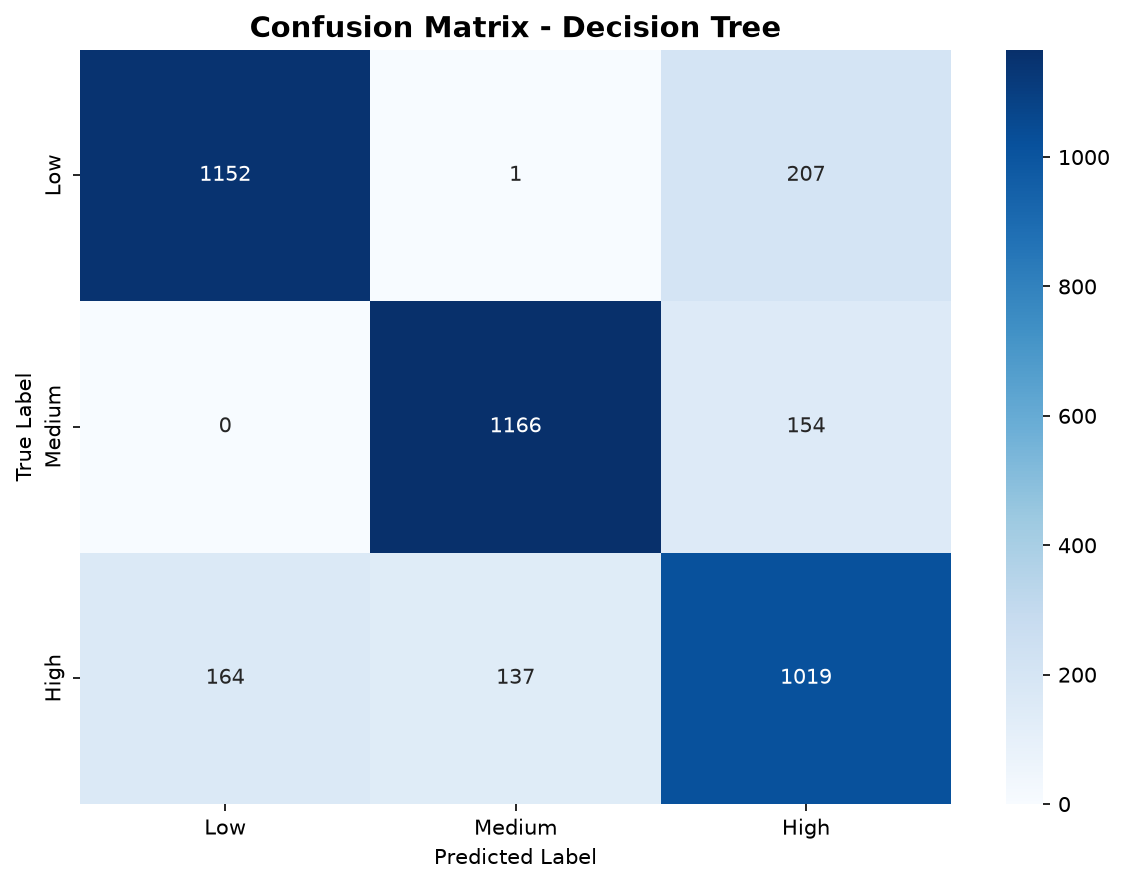

confusion_matrix_logistic_regression.png


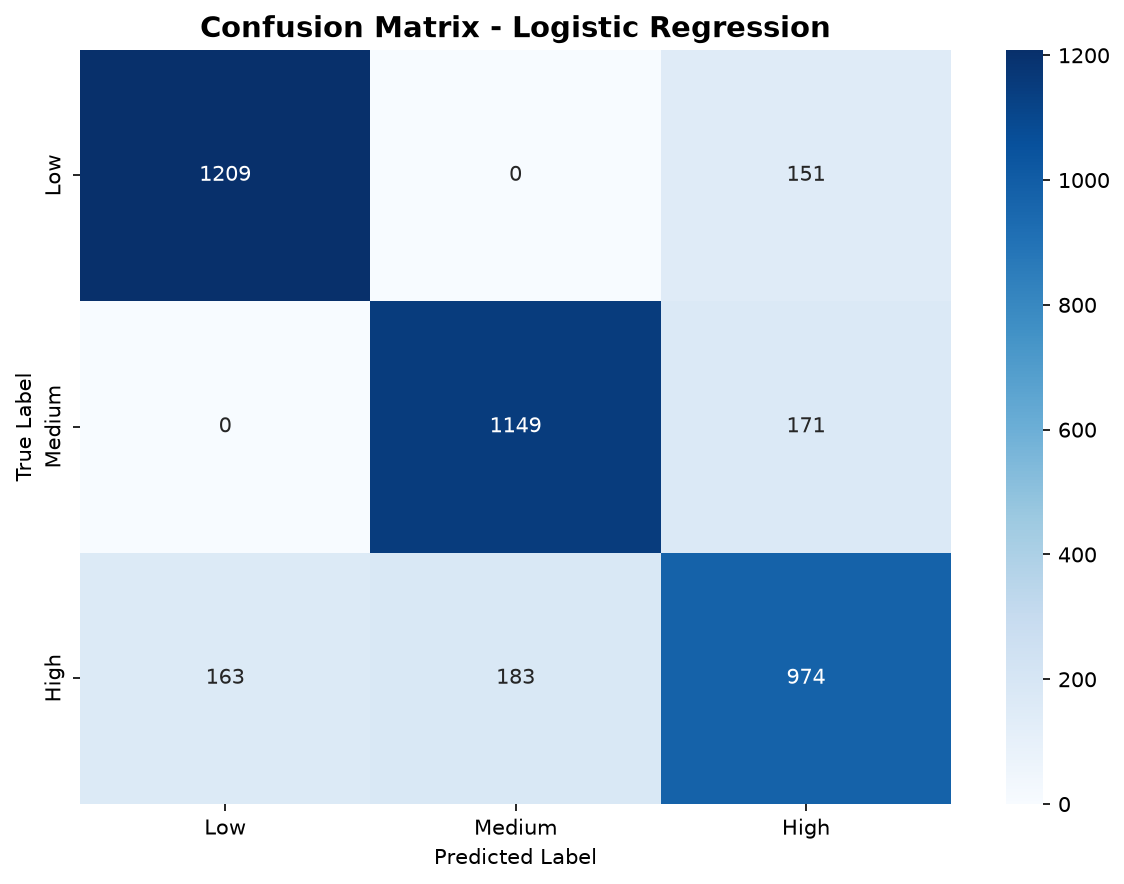

confusion_matrix_random_forest.png


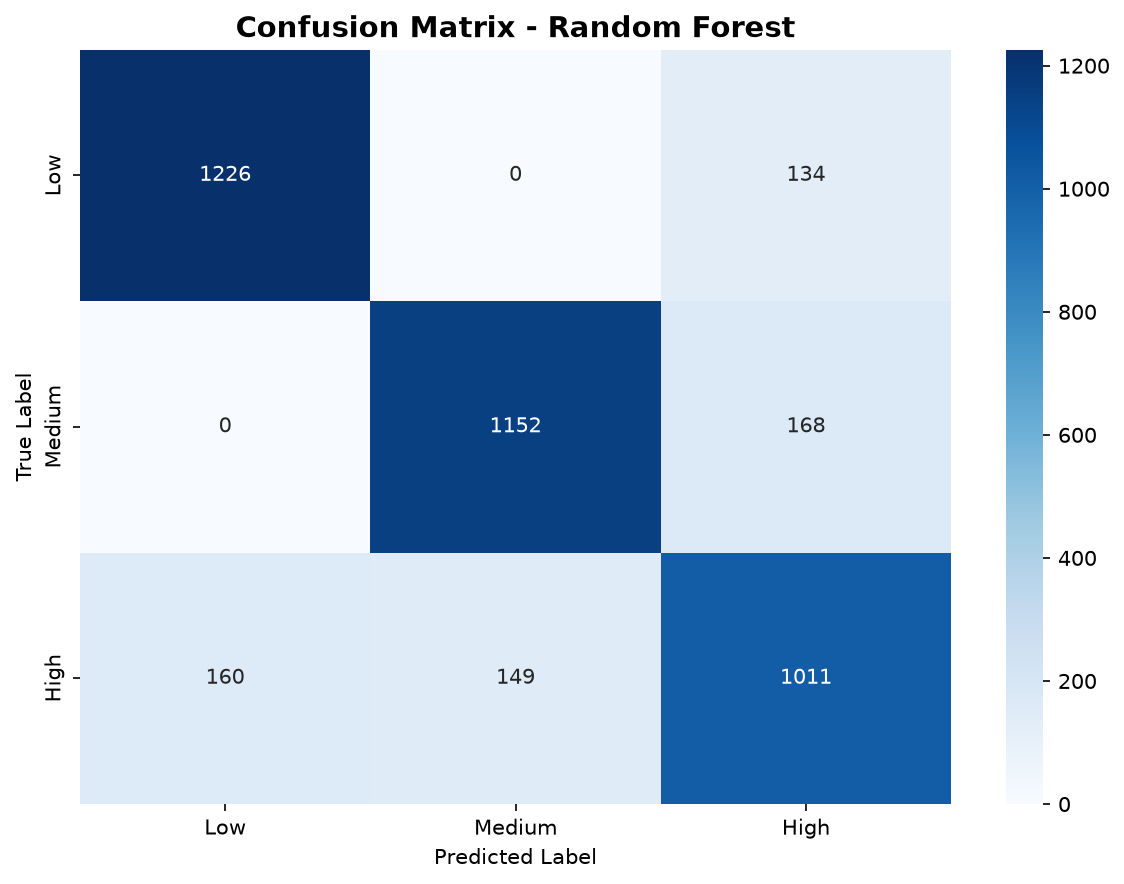

roc_curve_decision_tree.png


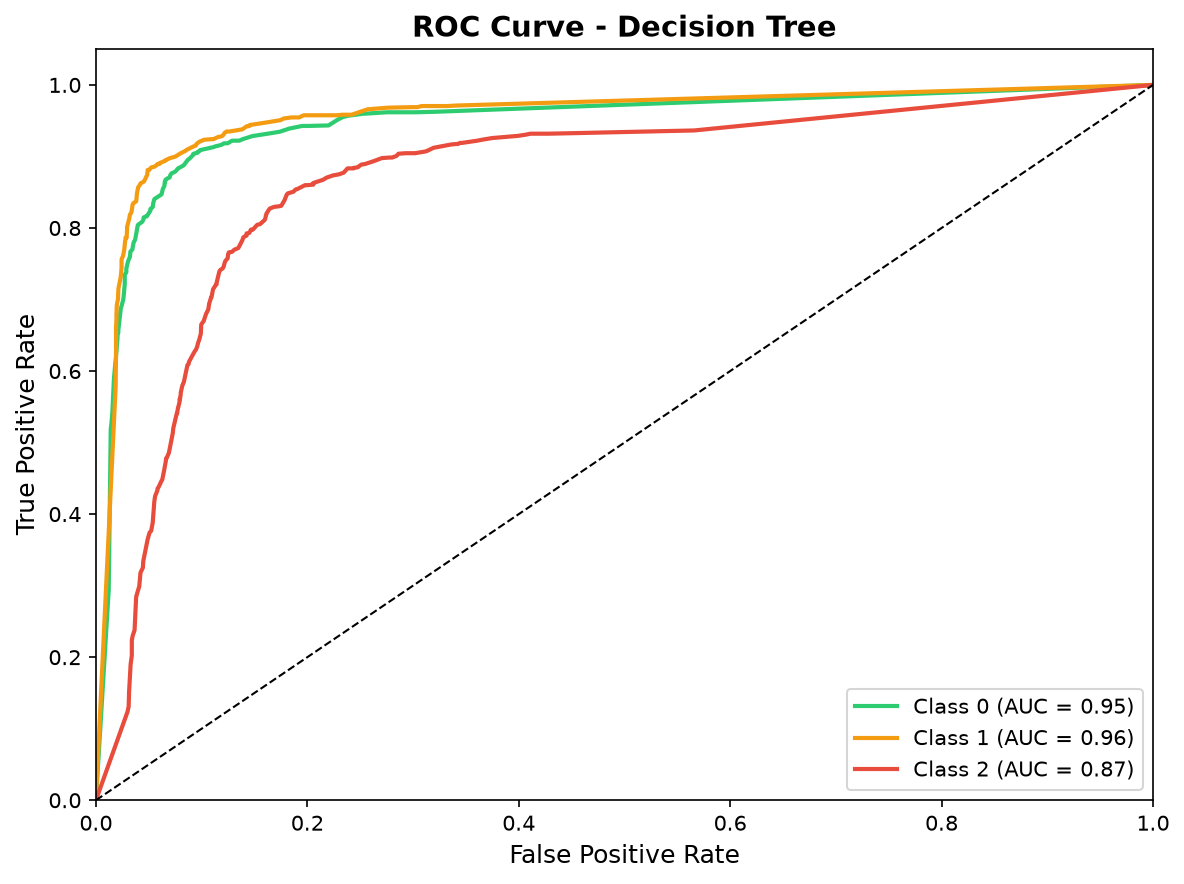

roc_curve_logistic_regression.png


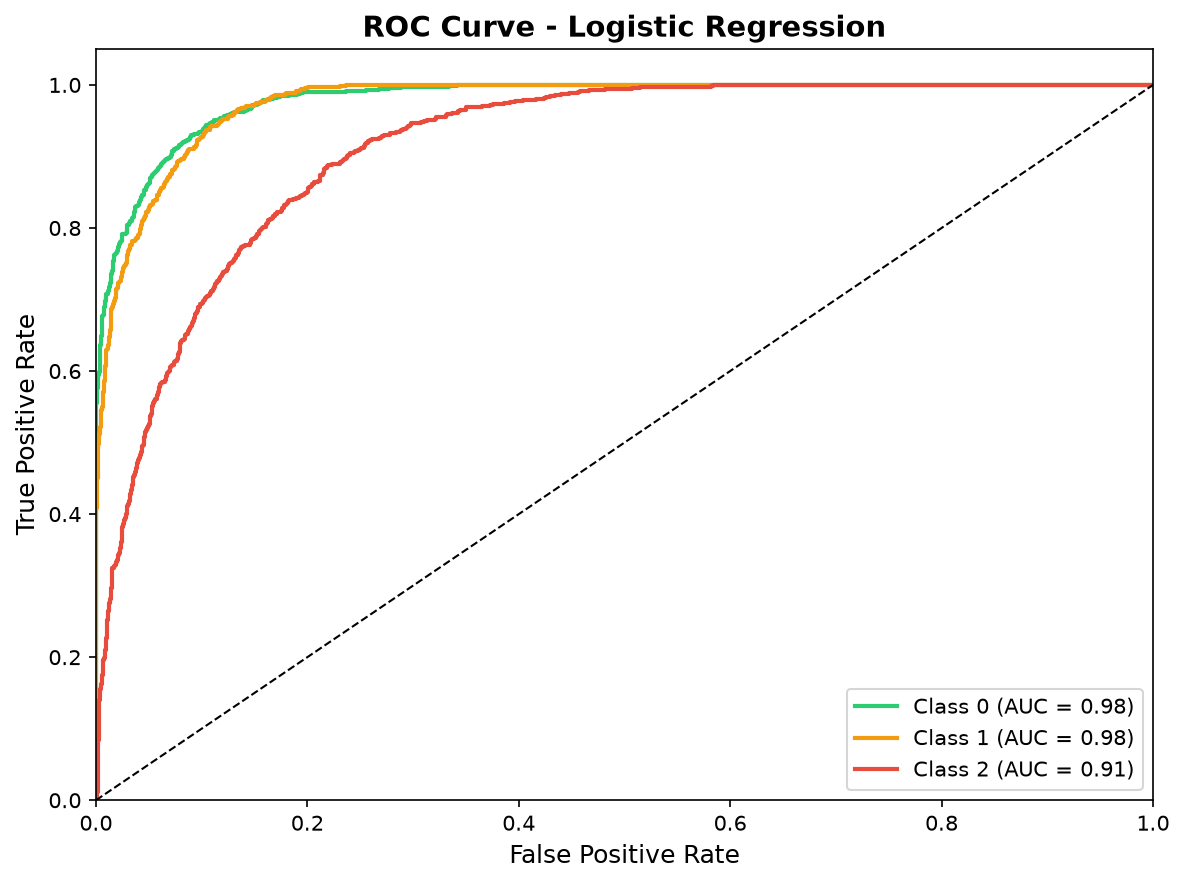

roc_curve_random_forest.png


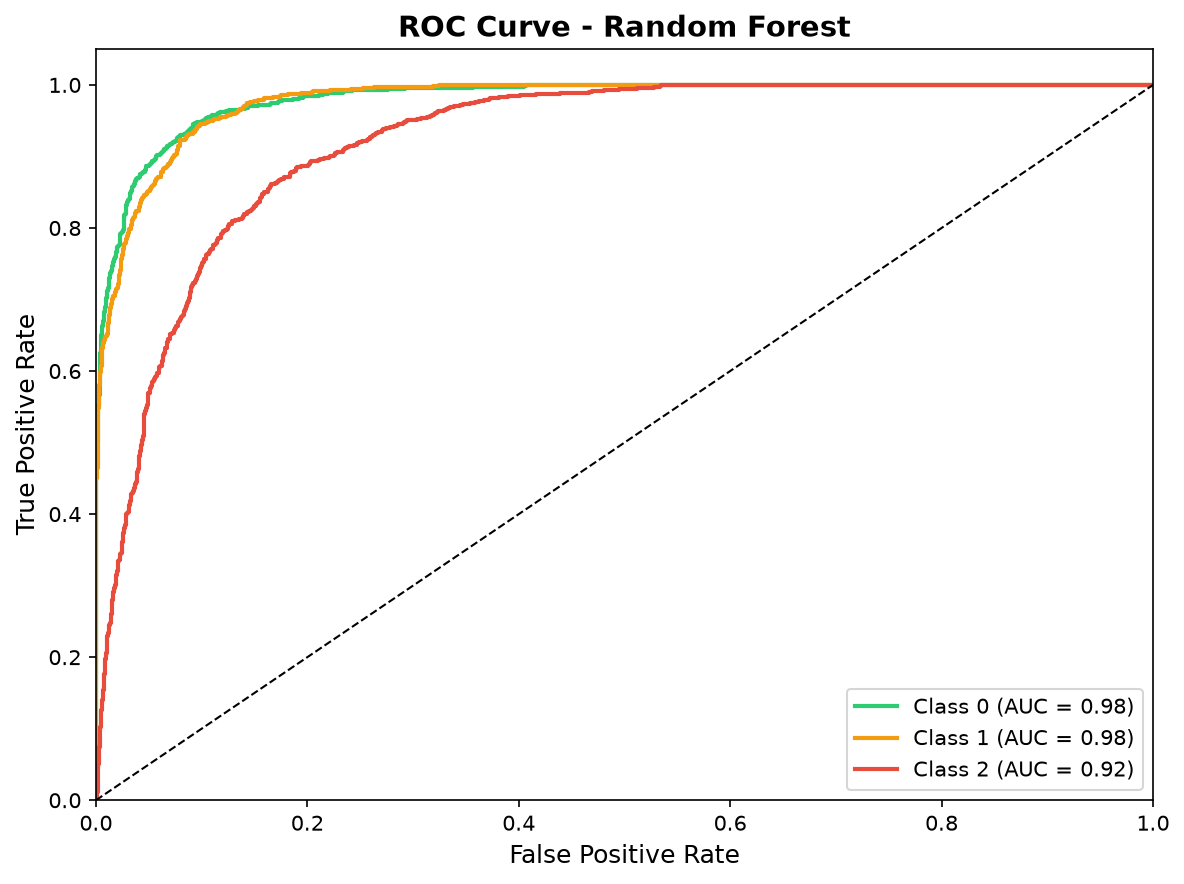

In [27]:
import sys, os
sys.path.append(os.path.abspath(".."))

from src.model_evaluation import evaluate_all_models, save_evaluation_report
from IPython.display import display, Image
import glob

all_results = evaluate_all_models(
    trained_models, X_test, y_test, output_dir=config.CHARTS_OUTPUT_DIR
)
save_evaluation_report(all_results, config.EVALUATION_REPORT_PATH)
print("Best model:", best_model_name)

charts = config.CHARTS_OUTPUT_DIR
eval_pngs = sorted(glob.glob(os.path.join(charts, "confusion_matrix_*.png")))
eval_pngs += sorted(glob.glob(os.path.join(charts, "roc_curve_*.png")))
for f in eval_pngs:
    print(os.path.basename(f))
    display(Image(filename=f, width=700))


## Month-3: Predictions

In [28]:
import sys, os
sys.path.append(os.path.abspath(".."))

from src.prediction import run_predictions

best_model = trained_models[best_model_name]["model"]
predictions_df = run_predictions(
    best_model, scaler, encoders, X_test, y_test, config
)
predictions_df.head()


######################################################################
# MAKING PREDICTIONS
######################################################################

[Prediction] Making batch predictions...
  Predictions made for 4000 samples

[Prediction] Saving predictions to: C:\Users\Easyskill-Saurabh\Desktop\AI-Impact-Jobs-Layoff-Risk\outputs\predictions\predictions.csv
  Predictions saved successfully!

--- Sample Predictions ---
       actual_risk predicted_risk  prob_High  prob_Low  prob_Medium
9477             1            Low     0.0793    0.4990       0.4217
6505             1            Low     0.0793    0.4990       0.4217
19902            2            Low     0.0893    0.4676       0.4431
14255            2            Low     0.0793    0.4990       0.4217
16321            2            Low     0.0793    0.4990       0.4217
4807             0            Low     0.1788    0.4221       0.3990
8429             1            Low     0.0793    0.4990       0.4217
783              

,age,education_level,years_of_experience,industry,job_role,company_size,job_level,routine_task_percentage,creativity_requirement,human_interaction_level,...,human_ai_balance,high_automation_risk,low_creativity_risk,high_routine_risk,low_interaction_risk,actual_risk,predicted_risk,prob_High,prob_Low,prob_Medium
9477,-0.551924,-0.893846,-1.115457,-0.658057,-0.364631,-0.073973,0.416559,-1.182030,1.119291,-1.304831,...,-0.363573,-0.271708,-0.624228,-0.622372,-0.365066,1,Low,0.0793,0.4990,0.4217
6505,1.096517,-0.893846,-0.056244,-0.658057,-0.364631,-1.423850,-0.978482,-1.386636,1.540750,0.311893,...,0.814563,-0.271708,-0.624228,-0.622372,-0.365066,1,Low,0.0793,0.4990,0.4217
19902,-0.985724,-0.893846,0.155598,0.649471,0.504538,-1.423850,1.811600,0.127449,0.084801,-1.439558,...,-0.461751,-0.271708,-0.624228,-0.622372,2.739234,2,Low,0.0893,0.4676,0.4431
14255,1.617077,-0.893846,-0.056244,0.213628,1.663430,-1.423850,-0.978482,-0.854660,1.195920,0.491529,...,0.945467,-0.271708,-0.624228,-0.622372,-0.365066,2,Low,0.0793,0.4990,0.4217
16321,-1.506284,-0.893846,-1.115457,-1.093899,-0.944077,1.275904,0.416559,-1.100188,1.425806,-0.182106,...,0.454577,-0.271708,-0.624228,-0.622372,-0.365066,2,Low,0.0793,0.4990,0.4217
